<a href="https://colab.research.google.com/github/Sujalkahahai/Social_Media_Analytics_CA2/blob/main/Social_Media_Analytics_CA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ADMT CA2: Social Media Analytics — Integrated ETL and OLAP Implementation

## 0. PROJECT INTRODUCTION

### Aim & Objectives
The aim of this project is to implement a complete, end-to-end data engineering pipeline—from raw synthetic source generation to an Operational OLAP Data Warehouse—demonstrating core Extract-Transform-Load (ETL) principles, relational schema modeling, and multidimensional analysis using OLAP operations.

### Technology Stack
* **Language**: Python 3 (Pandas, NumPy, Matplotlib, Seaborn)
* **Database Engine**: SQLite3 (Embedded relational database)
* **Environment**: Google Colab

### Complete Data Flow
```
[Raw Data Sources] -> [Extract (Pandas)] -> [Transform (Data Quality / Cleaning / Enrichment)] -> [Load (SQLite)]
                                                                                                |
[Insights / Charts / Exports] <- [OLAP Engine (SQL Queries)] <- [Star Schema Data Warehouse] <-
```

### Why SQLite is Suitable for this Demonstration
SQLite is an embedded, serverless, transactional SQL database engine. It requires zero configuration, stores the database in a single disk file, and perfectly supports advanced SQL constructs (constraints, joins, aggregation, transactions) without needing complex cloud or external server configurations. This makes it highly portable and ideal for academic demonstrations, reproducible research, and college vivas.

## 1. ENVIRONMENT SETUP

In this section, we import all required standard libraries, set seed variables globally to ensure deterministic operations, and construct the directory structures to store our project data, database, clean configurations, and exported charts.

In [1]:
import os
import pathlib
import json
import csv
import hashlib
import datetime
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shutil

# Ensure reproducibility by seeding randomly assigned values
GLOBAL_SEED = 51
np.random.seed(GLOBAL_SEED)
import random
random.seed(GLOBAL_SEED)

# Construct directories
BASE_DIR = pathlib.Path('/content/social_media_ca2')
subfolders = ['sources', 'warehouse', 'results', 'charts', 'evidence', 'exports']

for folder in subfolders:
    path = BASE_DIR / folder
    path.mkdir(parents=True, exist_ok=True)
    print(f"Directory prepared: {path}")

Directory prepared: /content/social_media_ca2/sources
Directory prepared: /content/social_media_ca2/warehouse
Directory prepared: /content/social_media_ca2/results
Directory prepared: /content/social_media_ca2/charts
Directory prepared: /content/social_media_ca2/evidence
Directory prepared: /content/social_media_ca2/exports


## 2. SOURCE DATA GENERATION

This section programmatically constructs the source dataset files with explicit random states, following the exact contract required by our data specifications:
* **creators.csv**: 60 unique creator records covering mapped countries and regions.
* **campaigns.json**: 3 distinct digital marketing campaigns representing corporate objectives.
* **posts.csv**: Exactly 1204 posts, containing 1200 unique valid records, 1 identical duplicate, and 3 deliberately invalid rows designed to test our pipeline's validation rules.
* **manifest.json**: Verification file tracking MD5/SHA-256 hashes and row counts.

In [2]:
import json
import hashlib
import pandas as pd
import numpy as np

# Configure seeds
np.random.seed(51)
import random
random.seed(51)

# 1. Generate Creators Dataset (60 records)
countries_regions = [
    ("United States", "North America"),
    ("Canada", "North America"),
    ("United Kingdom", "Europe"),
    ("Germany", "Europe"),
    ("France", "Europe"),
    ("Singapore", "Asia-Pacific"),
    ("Australia", "Asia-Pacific"),
    ("Japan", "Asia-Pacific")
]

creators_data = []
for i in range(1, 61):
    creator_id = f"CRT{i:03d}"
    creator_name = f"Creator {i}"
    country, region = countries_regions[(i - 1) % len(countries_regions)]
    creators_data.append({
        "creator_id": creator_id,
        "creator_name": creator_name,
        "country_name": country,
        "region_name": region
    })

df_creators = pd.DataFrame(creators_data)
df_creators.to_csv('/content/social_media_ca2/sources/creators.csv', index=False)

# 2. Generate Campaigns Dataset (3 records)
campaigns_data = [
    {"campaign_id": "CMP001", "campaign_name": "Global Brand Awareness", "objective": "Awareness"},
    {"campaign_id": "CMP002", "campaign_name": "Social Engagement Drive", "objective": "Engagement"},
    {"campaign_id": "CMP003", "campaign_name": "Winter Conversion Push", "objective": "Conversion"}
]

with open('/content/social_media_ca2/sources/campaigns.json', 'w') as f:
    json.dump(campaigns_data, f, indent=4)

# 3. Generate Posts Dataset (1204 records)
platforms = ["Instagram", "YouTube", "LinkedIn"]
content_types = ["Image", "Video", "Text"]
campaign_ids = ["CMP001", "CMP002", "CMP003"]

# Generate 1200 valid base records distributed over the year 2025
start_date = datetime.date(2025, 1, 1)
posts_data = []

for i in range(1, 1201):
    post_id = f"PST{i:05d}"
    days_offset = int((i - 1) * 364 / 1199) # Distribute evenly over 365 days of 2025
    posted_date = start_date + datetime.timedelta(days=days_offset)
    # Introduce some variation using global seeds
    platform = platforms[(i * 17) % len(platforms)]
    content_type = content_types[(i * 23) % len(content_types)]
    creator_id = f"CRT{(i * 13) % 60 + 1:03d}"
    campaign_id = campaign_ids[(i * 31) % len(campaign_ids)]

    # Generate typical metrics depending on platforms
    base_imp = 10000 if platform == "YouTube" else (6000 if platform == "Instagram" else 3000)
    impressions = int(np.random.normal(base_imp, base_imp * 0.2))
    impressions = max(100, impressions) # Guarantee natural non-zero values

    # Determine engagements
    eng_rate = 0.04 + 0.01 * np.sin(i)
    engagements = int(impressions * eng_rate)
    likes = int(engagements * 0.7)
    comments = int(engagements * 0.2)
    shares = max(0, engagements - (likes + comments))

    posts_data.append({
        "post_id": post_id,
        "posted_at": posted_date.strftime("%Y-%m-%d 12:00:00"),
        "platform": platform,
        "creator_id": creator_id,
        "content_type": content_type,
        "campaign_id": campaign_id,
        "likes": likes,
        "comments": comments,
        "shares": shares,
        "impressions": impressions
    })

# Inject specific anomalistic/edge cases into our 1200 valid records:
# Case A: One zero-impression post with zero engagement so its rate is undefined but is accepted.
posts_data[100]['impressions'] = 0
posts_data[100]['likes'] = 0
posts_data[100]['comments'] = 0
posts_data[100]['shares'] = 0

# Case B: One valid record with an unknown creator reference to test dimension fallbacks.
posts_data[200]['creator_id'] = "CRT999"

# Case C: One valid record with an unknown campaign reference to test dimension fallbacks.
posts_data[300]['campaign_id'] = "CMP999"

# Case D: One valid record with a missing optional content type label.
posts_data[400]['content_type'] = ""

# Append exactly 1 exact identical row (making row 1201)
duplicate_row = posts_data[0].copy()
posts_data.append(duplicate_row)

# Append 3 deliberately invalid records to test filtering & rejection (rows 1202, 1203, 1204)
invalid_1 = {
    "post_id": "PST_INV_1",
    "posted_at": "2025-13-45 12:00:00", # Malformed date
    "platform": "Instagram",
    "creator_id": "CRT001",
    "content_type": "Image",
    "campaign_id": "CMP001",
    "likes": -100,
    "comments": 10,
    "shares": 5,
    "impressions": 500
}
invalid_2 = {
    "post_id": "", # Missing key primary identifier
    "posted_at": "2025-05-01 12:00:00",
    "platform": "YouTube",
    "creator_id": "CRT002",
    "content_type": "Video",
    "campaign_id": "CMP002",
    "likes": 200,
    "comments": 50,
    "shares": 10,
    "impressions": -1000 # Negative scale
}
invalid_3 = {
    "post_id": "PST_INV_3",
    "posted_at": "2025-06-15 00:00:00",
    "platform": "TikTok_Unsupported", # Invalid dimension constraint
    "creator_id": "CRT003",
    "content_type": "Text",
    "campaign_id": "CMP003",
    "likes": 100,
    "comments": 20,
    "shares": 10,
    "impressions": 500
}
posts_data.extend([invalid_1, invalid_2, invalid_3])

# Create DataFrame & export to raw sources directory
df_posts = pd.DataFrame(posts_data)
df_posts.to_csv('/content/social_media_ca2/sources/posts.csv', index=False)

# Helper function to compute hash for manifest verification
def compute_sha256(filepath):
    sha256_hash = hashlib.sha256()
    with open(filepath, "rb") as f:
        for byte_block in iter(lambda: f.read(4096), b""):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

manifest = {
    "generation_timestamp_utc": datetime.datetime.utcnow().isoformat(),
    "origin": "synthetic",
    "files": [
        {
            "filename": "posts.csv",
            "expected_rows": len(df_posts),
            "sha256": compute_sha256('/content/social_media_ca2/sources/posts.csv')
        },
        {
            "filename": "creators.csv",
            "expected_rows": len(df_creators),
            "sha256": compute_sha256('/content/social_media_ca2/sources/creators.csv')
        },
        {
            "filename": "campaigns.json",
            "expected_items": len(campaigns_data),
            "sha256": compute_sha256('/content/social_media_ca2/sources/campaigns.json')
        }
    ]
}

with open('/content/social_media_ca2/sources/manifest.json', 'w') as mf:
    json.dump(manifest, mf, indent=4)

print("Source Generation Complete.")
print(f"Raw Posts Shape: {df_posts.shape}")
print(f"Creators Shape: {df_creators.shape}")

Source Generation Complete.
Raw Posts Shape: (1204, 10)
Creators Shape: (60, 4)


/tmp/ipykernel_4647/3156409790.py:164: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "generation_timestamp_utc": datetime.datetime.utcnow().isoformat(),


## 3. EXTRACT

To simulate a production ETL system, we explicitly load the raw files from the filesystem using `pd.read_csv` and Python's built-in `json` module, decoupling the memory state. We then display shape metrics and verify that all 1204 post records have been correctly extracted.

In [3]:
import json
import pandas as pd

# Extract source data from local storage files
extracted_posts = pd.read_csv('/content/social_media_ca2/sources/posts.csv')
extracted_creators = pd.read_csv('/content/social_media_ca2/sources/creators.csv')

with open('/content/social_media_ca2/sources/campaigns.json', 'r') as f:
    extracted_campaigns_list = json.load(f)
extracted_campaigns = pd.DataFrame(extracted_campaigns_list)

# Audit basic shapes
print("=== EXTRACT AUDIT SUMMARY ===")
print(f"Extracted Raw Posts Rows: {len(extracted_posts)}")
print(f"Extracted Creators Rows: {len(extracted_creators)}")
print(f"Extracted Campaigns Rows: {len(extracted_campaigns)}")

# Display sample frames
print("\n--- Raw Posts (First 5 Rows) ---")
display(extracted_posts.head(5))

print("\n--- Campaigns Data ---")
display(extracted_campaigns)

print("\n--- Creators Data (First 5 Rows) ---")
display(extracted_creators.head(5))

=== EXTRACT AUDIT SUMMARY ===
Extracted Raw Posts Rows: 1204
Extracted Creators Rows: 60
Extracted Campaigns Rows: 3

--- Raw Posts (First 5 Rows) ---


,post_id,posted_at,platform,creator_id,content_type,campaign_id,likes,comments,shares,impressions
0,PST00001,2025-01-01 12:00:00,LinkedIn,CRT014,Text,CMP002,95,27,14,2825
1,PST00002,2025-01-01 12:00:00,YouTube,CRT027,Video,CMP003,350,100,51,10224
2,PST00003,2025-01-01 12:00:00,Instagram,CRT040,Image,CMP001,217,62,31,7500
3,PST00004,2025-01-01 12:00:00,LinkedIn,CRT053,Text,CMP002,49,14,7,2183
4,PST00005,2025-01-02 12:00:00,YouTube,CRT006,Video,CMP003,217,62,31,10199



--- Campaigns Data ---


,campaign_id,campaign_name,objective
0,CMP001,Global Brand Awareness,Awareness
1,CMP002,Social Engagement Drive,Engagement
2,CMP003,Winter Conversion Push,Conversion



--- Creators Data (First 5 Rows) ---


,creator_id,creator_name,country_name,region_name
0,CRT001,Creator 1,United States,North America
1,CRT002,Creator 2,Canada,North America
2,CRT003,Creator 3,United Kingdom,Europe
3,CRT004,Creator 4,Germany,Europe
4,CRT005,Creator 5,France,Europe


## 4. DATA QUALITY AND CLEANING

In this section, we apply quality filtering rules to separate our raw extracted posts into clean records and rejected anomalies.

### Validation Rules:
1. **Primary Key Integrity**: `post_id` must be present and non-empty.
2. **Platform Domain Integrity**: `platform` must belong to the approved domain (Instagram, YouTube, LinkedIn).
3. **Date Formats**: `posted_at` must parse into a valid datetime object.
4. **Metric Integrity**: Numeric metrics (`likes`, `comments`, `shares`, `impressions`) must be non-negative.
5. **Duplicate Handling**: Exact repeated `post_id` instances must be identified and de-duplicated (retaining the first occurrence).

Rejected records will be saved to `results/rejected_posts.csv` with an explicit reason column.

In [4]:
import pandas as pd
import numpy as np

raw_posts_df = extracted_posts.copy()

# Prepare lists for sorting accepted/rejected records
accepted_rows = []
rejected_rows = []
seen_post_ids = set()
duplicate_count = 0

for idx, row in raw_posts_df.iterrows():
    post_id = str(row.get('post_id', '')).strip()
    platform = str(row.get('platform', '')).strip()
    posted_at = str(row.get('posted_at', '')).strip()

    # Convert metrics safely
    try:
        likes = int(row.get('likes', 0))
        comments = int(row.get('comments', 0))
        shares = int(row.get('shares', 0))
        impressions = int(row.get('impressions', 0))
    except (ValueError, TypeError):
        likes, comments, shares, impressions = -1, -1, -1, -1

    # Validation Checks
    if not post_id or post_id == 'nan' or post_id == '':
        row_dict = row.to_dict()
        row_dict['rejection_reason'] = "Missing post_id primary identifier"
        rejected_rows.append(row_dict)
        continue

    if platform not in ["Instagram", "YouTube", "LinkedIn"]:
        row_dict = row.to_dict()
        row_dict['rejection_reason'] = f"Unsupported platform: {platform}"
        rejected_rows.append(row_dict)
        continue

    # Parse and validate date string
    try:
        valid_dt = pd.to_datetime(posted_at, format="%Y-%m-%d %H:%M:%S")
        if pd.isna(valid_dt):
            raise ValueError
    except Exception:
        row_dict = row.to_dict()
        row_dict['rejection_reason'] = f"Malformed date value: {posted_at}"
        rejected_rows.append(row_dict)
        continue

    # Validate positive metrics
    if likes < 0 or comments < 0 or shares < 0 or impressions < 0:
        row_dict = row.to_dict()
        row_dict['rejection_reason'] = "Negative metric values detected"
        rejected_rows.append(row_dict)
        continue

    # Duplicate Check
    if post_id in seen_post_ids:
        # Ensure it is an exact duplicate, check details matching original
        duplicate_count += 1
        continue

    seen_post_ids.add(post_id)
    accepted_rows.append(row.to_dict())

# Create resulting DataFrames
df_accepted = pd.DataFrame(accepted_rows)
df_rejected = pd.DataFrame(rejected_rows)

# Save rejected to csv
df_rejected.to_csv('/content/social_media_ca2/results/rejected_posts.csv', index=False)

# Print detailed verification numbers
print("=== DATA QUALITY AND RECONCILIATION SUMMARY ===")
print(f"Raw Inputs Extracted : {len(raw_posts_df)}")
print(f"Accepted Valid Posts : {len(df_accepted)}")
print(f"Rejected Invalid Posts: {len(df_rejected)}")
print(f"Identified Duplicates : {duplicate_count}")

# Show evidence of the rejection reasons
print("\n--- Rejected Records with Rejection Reasons ---")
display(df_rejected[['post_id', 'platform', 'posted_at', 'rejection_reason']])

# Assert absolute reconciliation integrity
assert len(df_accepted) + len(df_rejected) + duplicate_count == len(raw_posts_df), \
    f"Reconciliation error: {len(df_accepted)} + {len(df_rejected)} + {duplicate_count} != {len(raw_posts_df)}"
print("\n[PASSED] Reconciliation assert validated successfully!")

=== DATA QUALITY AND RECONCILIATION SUMMARY ===
Raw Inputs Extracted : 1204
Accepted Valid Posts : 1200
Rejected Invalid Posts: 3
Identified Duplicates : 1

--- Rejected Records with Rejection Reasons ---


,post_id,platform,posted_at,rejection_reason
0,PST_INV_1,Instagram,2025-13-45 12:00:00,Malformed date value: 2025-13-45 12:00:00
1,NaN,YouTube,2025-05-01 12:00:00,Missing post_id primary identifier
2,PST_INV_3,TikTok_Unsupported,2025-06-15 00:00:00,Unsupported platform: TikTok_Unsupported



[PASSED] Reconciliation assert validated successfully!


## 5. TRANSFORM AND INTEGRATE

In this step, we prepare our data for load by translating columns into structural components suitable for dimensional modeling:
1. **Data Normalization**: Clean categorical descriptors for platform and content classifications (handling missing optional content types by filling them as `'Unknown'`).
2. **Date Deconstruction**: Convert strings into dynamic components (`calendar_year`, `calendar_quarter`, `calendar_month`, `calendar_day`).
3. **Metric Calculations**: Compute `engagements` as `likes + comments + shares`. Calculate `engagement_pct` safely, returning `None` or `NaN` if `impressions == 0` to prevent division-by-zero errors.
4. **Entity Integrity & Joins**: Map `creator_id` and `campaign_id` to referenced dimensional metadata. Replace missing references (like our test CRT999 and CMP999 rows) with an explicit `'Unknown'` fallback, keeping our row count consistent at 1200.

In [5]:
import pandas as pd
import numpy as np

transformed_df = df_accepted.copy()

# Convert timestamps and extract date parts
transformed_df['posted_at_parsed'] = pd.to_datetime(transformed_df['posted_at'], format="%Y-%m-%d %H:%M:%S")
transformed_df['full_date'] = transformed_df['posted_at_parsed'].dt.strftime('%Y-%m-%d')
transformed_df['calendar_year'] = transformed_df['posted_at_parsed'].dt.year
transformed_df['calendar_quarter'] = transformed_df['posted_at_parsed'].dt.quarter
transformed_df['calendar_month'] = transformed_df['posted_at_parsed'].dt.month
transformed_df['calendar_day'] = transformed_df['posted_at_parsed'].dt.day

# Clean content type and map empty strings to 'Unknown'
transformed_df['content_type'] = transformed_df['content_type'].fillna('Unknown')
transformed_df.loc[transformed_df['content_type'] == '', 'content_type'] = 'Unknown'

# Metric calculations
transformed_df['likes'] = transformed_df['likes'].astype(int)
transformed_df['comments'] = transformed_df['comments'].astype(int)
transformed_df['shares'] = transformed_df['shares'].astype(int)
transformed_df['impressions'] = transformed_df['impressions'].astype(int)

transformed_df['engagements'] = transformed_df['likes'] + transformed_df['comments'] + transformed_df['shares']

# Calculate individual percentage safely (NaN if impressions == 0)
transformed_df['engagement_pct'] = np.where(
    transformed_df['impressions'] > 0,
    (transformed_df['engagements'] / transformed_df['impressions']) * 100,
    np.nan
)

# Align creator metadata; provide 'Unknown' fallback
creators_map = df_creators.set_index('creator_id').to_dict('index')
def map_creator(row):
    cid = row['creator_id']
    if cid in creators_map:
        return creators_map[cid]['creator_name'], creators_map[cid]['country_name'], creators_map[cid]['region_name']
    return "Unknown Creator", "Unknown Country", "Unknown Region"

transformed_df[['creator_name', 'country_name', 'region_name']] = transformed_df.apply(
    lambda r: pd.Series(map_creator(r)), axis=1
)

# Align campaign metadata; provide 'Unknown' fallback
campaigns_map = extracted_campaigns.set_index('campaign_id').to_dict('index')
def map_campaign(row):
    cid = row['campaign_id']
    if cid in campaigns_map:
        return campaigns_map[cid]['campaign_name'], campaigns_map[cid]['objective']
    return "Unknown Campaign", "Unknown Objective"

transformed_df[['campaign_name', 'objective']] = transformed_df.apply(
    lambda r: pd.Series(map_campaign(r)), axis=1
)

# Verify final transformation properties
print("=== TRANSFORMATION AUDIT ===")
print(f"Post-Transformation Row Count: {len(transformed_df)} (Target: 1200)")
assert len(transformed_df) == 1200, "Transformation altered accepted row count!"

# Show samples of anomalous fallbacks handling
print("\n--- Verification: Missing Content Type mapped to Unknown ---")
display(transformed_df[transformed_df['post_id'] == 'PST00401'][['post_id', 'content_type']])

print("\n--- Verification: Unresolved Creator CRT999 mapped to Unknown Creator ---")
display(transformed_df[transformed_df['post_id'] == 'PST00201'][['post_id', 'creator_id', 'creator_name', 'region_name']])

print("\n--- Verification: Unresolved Campaign CMP999 mapped to Unknown Campaign ---")
display(transformed_df[transformed_df['post_id'] == 'PST00301'][['post_id', 'campaign_id', 'campaign_name', 'objective']])

=== TRANSFORMATION AUDIT ===
Post-Transformation Row Count: 1200 (Target: 1200)

--- Verification: Missing Content Type mapped to Unknown ---


,post_id,content_type
400,PST00401,Unknown



--- Verification: Unresolved Creator CRT999 mapped to Unknown Creator ---


,post_id,creator_id,creator_name,region_name
200,PST00201,CRT999,Unknown Creator,Unknown Region



--- Verification: Unresolved Campaign CMP999 mapped to Unknown Campaign ---


,post_id,campaign_id,campaign_name,objective
300,PST00301,CMP999,Unknown Campaign,Unknown Objective


## 6. DATA WAREHOUSE STAR SCHEMA

In this section, we instantiate a physical SQLite database (`warehouse/social_media_ca2_dw.sqlite`) and design an optimized star schema.

### Relational Modeling Components:
* **Dimension Tables**: `dim_date`, `dim_platform`, `dim_creator`, `dim_content`, `dim_campaign`.
* **Fact Table**: `fact_post` (Grain: One row per accepted post).
* **Referential Integrity**: Managed via foreign keys (`PRAGMA foreign_keys = ON`).
* **Idempotency**: All tables are dropped and recreated on execution to ensure clean, isolated states.
* **Default Members**: Row ID `0` is initialized in dimensions for default handling of unresolved mappings.

In [6]:
import sqlite3

DB_PATH = '/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite'
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

# Enforce referential integrity constraints
cursor.execute("PRAGMA foreign_keys = ON;")

# Drop tables if they already exist
cursor.execute("DROP TABLE IF EXISTS fact_post;")
cursor.execute("DROP TABLE IF EXISTS dim_date;")
cursor.execute("DROP TABLE IF EXISTS dim_platform;")
cursor.execute("DROP TABLE IF EXISTS dim_creator;")
cursor.execute("DROP TABLE IF EXISTS dim_content;")
cursor.execute("DROP TABLE IF EXISTS dim_campaign;")

# 1. Create dim_date
cursor.execute("""
CREATE TABLE dim_date (
    date_key INTEGER PRIMARY KEY,
    full_date TEXT NOT NULL UNIQUE,
    calendar_year INTEGER NOT NULL,
    calendar_quarter INTEGER NOT NULL,
    calendar_month INTEGER NOT NULL,
    calendar_day INTEGER NOT NULL
);
""")

# 2. Create dim_platform
cursor.execute("""
CREATE TABLE dim_platform (
    platform_key INTEGER PRIMARY KEY AUTOINCREMENT,
    platform_name TEXT NOT NULL UNIQUE
);
""")

# 3. Create dim_creator
cursor.execute("""
CREATE TABLE dim_creator (
    creator_key INTEGER PRIMARY KEY AUTOINCREMENT,
    creator_id TEXT NOT NULL UNIQUE,
    creator_name TEXT NOT NULL,
    country_name TEXT NOT NULL,
    region_name TEXT NOT NULL
);
""")

# 4. Create dim_content
cursor.execute("""
CREATE TABLE dim_content (
    content_key INTEGER PRIMARY KEY AUTOINCREMENT,
    content_type TEXT NOT NULL UNIQUE
);
""")

# 5. Create dim_campaign
cursor.execute("""
CREATE TABLE dim_campaign (
    campaign_key INTEGER PRIMARY KEY AUTOINCREMENT,
    campaign_id TEXT NOT NULL UNIQUE,
    campaign_name TEXT NOT NULL,
    objective TEXT NOT NULL
);
""")

# 6. Create fact_post
cursor.execute("""
CREATE TABLE fact_post (
    post_key INTEGER PRIMARY KEY AUTOINCREMENT,
    post_id TEXT NOT NULL UNIQUE,
    date_key INTEGER NOT NULL,
    platform_key INTEGER NOT NULL,
    creator_key INTEGER NOT NULL,
    content_key INTEGER NOT NULL,
    campaign_key INTEGER NOT NULL,
    likes INTEGER NOT NULL CHECK(likes >= 0),
    comments INTEGER NOT NULL CHECK(comments >= 0),
    shares INTEGER NOT NULL CHECK(shares >= 0),
    impressions INTEGER NOT NULL CHECK(impressions >= 0),
    engagements INTEGER NOT NULL CHECK(engagements >= 0),
    FOREIGN KEY (date_key) REFERENCES dim_date(date_key),
    FOREIGN KEY (platform_key) REFERENCES dim_platform(platform_key),
    FOREIGN KEY (creator_key) REFERENCES dim_creator(creator_key),
    FOREIGN KEY (content_key) REFERENCES dim_content(content_key),
    FOREIGN KEY (campaign_key) REFERENCES dim_campaign(campaign_key)
);
""")

# Create a composite performance index on foreign keys
cursor.execute("CREATE INDEX idx_fact_post_date_plat ON fact_post(date_key, platform_key);")
conn.commit()
print("Database tables and indexes created successfully.")

Database tables and indexes created successfully.


In [7]:
# Populate Dimensions

# A. Seed default 'Unknown' records first (ID 0) where supported
# For SQLite, AUTOINCREMENT key begins at 1. We manually inject key 0 with INSERT statements.
cursor.execute("INSERT INTO dim_creator (creator_key, creator_id, creator_name, country_name, region_name) VALUES (0, 'CRT000', 'Unknown Creator', 'Unknown Country', 'Unknown Region');")
cursor.execute("INSERT INTO dim_campaign (campaign_key, campaign_id, campaign_name, objective) VALUES (0, 'CMP000', 'Unknown Campaign', 'Unknown Objective');")
cursor.execute("INSERT INTO dim_content (content_key, content_type) VALUES (0, 'Unknown');")

# B. Populating dim_date (based on the year 2025)
dates = pd.date_range(start="2025-01-01", end="2025-12-31")
for dt in dates:
    date_key = int(dt.strftime("%Y%m%d"))
    cursor.execute("""
        INSERT INTO dim_date (date_key, full_date, calendar_year, calendar_quarter, calendar_month, calendar_day)
        VALUES (?, ?, ?, ?, ?, ?)
    """, (date_key, dt.strftime("%Y-%m-%d"), dt.year, int((dt.month - 1) / 3 + 1), dt.month, dt.day))

# C. Populating dim_platform
unique_platforms = transformed_df['platform'].unique()
for plat in unique_platforms:
    cursor.execute("INSERT INTO dim_platform (platform_name) VALUES (?)", (plat,))

# D. Populating dim_creator
for _, r in df_creators.iterrows():
    cursor.execute("""
        INSERT INTO dim_creator (creator_id, creator_name, country_name, region_name)
        VALUES (?, ?, ?, ?)
    """, (r['creator_id'], r['creator_name'], r['country_name'], r['region_name']))

# E. Populating dim_content
unique_contents = [c for c in transformed_df['content_type'].unique() if c != 'Unknown']
for ct in unique_contents:
    cursor.execute("INSERT INTO dim_content (content_type) VALUES (?)", (ct,))

# F. Populating dim_campaign
for _, r in extracted_campaigns.iterrows():
    cursor.execute("""
        INSERT INTO dim_campaign (campaign_id, campaign_name, objective)
        VALUES (?, ?, ?)
    """, (r['campaign_id'], r['campaign_name'], r['objective']))

conn.commit()
print("Dimensions seeded successfully.")

Dimensions seeded successfully.


In [8]:
# Load Fact Table (fact_post)

# Read lookup dictionaries from created DB dimensions
platform_lookup = {r[1]: r[0] for r in cursor.execute("SELECT platform_key, platform_name FROM dim_platform").fetchall()}
creator_lookup = {r[1]: r[0] for r in cursor.execute("SELECT creator_key, creator_id FROM dim_creator").fetchall()}
content_lookup = {r[1]: r[0] for r in cursor.execute("SELECT content_key, content_type FROM dim_content").fetchall()}
campaign_lookup = {r[1]: r[0] for r in cursor.execute("SELECT campaign_key, campaign_id FROM dim_campaign").fetchall()}

fact_records = []
for _, r in transformed_df.iterrows():
    post_id = r['post_id']
    date_key = int(pd.to_datetime(r['full_date']).strftime("%Y%m%d"))

    # Foreign keys lookup with explicit default fallbacks (0) if not matched
    platform_key = platform_lookup.get(r['platform'])
    creator_key = creator_lookup.get(r['creator_id'], 0)
    content_key = content_lookup.get(r['content_type'], 0)
    campaign_key = campaign_lookup.get(r['campaign_id'], 0)

    likes = int(r['likes'])
    comments = int(r['comments'])
    shares = int(r['shares'])
    impressions = int(r['impressions'])
    engagements = int(r['engagements'])

    cursor.execute("""
        INSERT INTO fact_post (post_id, date_key, platform_key, creator_key, content_key, campaign_key, likes, comments, shares, impressions, engagements)
        VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
    """, (post_id, date_key, platform_key, creator_key, content_key, campaign_key, likes, comments, shares, impressions, engagements))

conn.commit()
print(f"Fact table populated successfully with {len(transformed_df)} records.")

Fact table populated successfully with 1200 records.


## 9. OLAP Q2 — DRILL-DOWN

A **Drill-down** breaks down consolidated values into finer geographical details. We execute this by first grouping posts at the Parent Level (`region_name`), and then drilling down into the Child Level (`region_name` and `country_name`).

* **Parent Level**: Regional metrics.
* **Child Level**: Regional and country metrics combined.

We verify that the sum of the country metrics matches the parent regional sums perfectly.

In [10]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# Parent level query
parent_query = """
SELECT
    c.region_name,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_creator c ON fp.creator_key = c.creator_key
GROUP BY c.region_name
ORDER BY total_posts DESC;
"""

# Child level (drill down) query
child_query = """
SELECT
    c.region_name,
    c.country_name,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_creator c ON fp.creator_key = c.creator_key
GROUP BY c.region_name, c.country_name
ORDER BY c.region_name, total_posts DESC;
"""

df_parent = pd.read_sql_query(parent_query, conn)
df_child = pd.read_sql_query(child_query, conn)

df_parent.to_csv('/content/social_media_ca2/results/Q2_parent.csv', index=False)
df_child.to_csv('/content/social_media_ca2/results/Q2.csv', index=False)

print("=== PARENT LEVEL (REGIONAL GROUPING) ===")
display(df_parent)

print("\n=== DRILL-DOWN LEVEL (REGION & COUNTRY GROUPING) ===")
display(df_child)

# Validate reconciliation
parent_tot = df_parent[df_parent['region_name'] != 'Unknown Region']['total_posts'].sum()
child_tot = df_child[df_child['region_name'] != 'Unknown Region']['total_posts'].sum()
assert parent_tot == child_tot, f"Reconciliation failed: parent total ({parent_tot}) != child total ({child_tot})"
print(f"\n[PASSED] Reconciliation check: Regional sum ({parent_tot}) matches Country sum ({child_tot})!")
conn.close()

=== PARENT LEVEL (REGIONAL GROUPING) ===


,region_name,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Europe,460,116249,2919793,3.98
1,Asia-Pacific,420,104623,2619672,3.99
2,North America,319,80918,2024373,4.00
3,Unknown Region,1,231,5882,3.93



=== DRILL-DOWN LEVEL (REGION & COUNTRY GROUPING) ===


,region_name,country_name,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Asia-Pacific,Singapore,140,37682,942577,4.00
1,Asia-Pacific,Japan,140,32616,818208,3.99
2,Asia-Pacific,Australia,140,34325,858887,4.00
3,Europe,United Kingdom,160,40917,1023970,4.00
4,Europe,Germany,160,43041,1085397,3.97
5,Europe,France,140,32291,810426,3.98
6,North America,United States,160,43456,1087727,4.00
7,North America,Canada,159,37462,936646,4.00
8,Unknown Region,Unknown Country,1,231,5882,3.93



[PASSED] Reconciliation check: Regional sum (1199) matches Country sum (1199)!


## 10. OLAP Q3 — SLICE

A **Slice** acts as a single-dimensional filter, extracting a sub-cube of the dataset by holding one dimension constant. Here, we analyze the platform dimension, selecting only rows where `platform_name = 'Instagram'` to display monthly metrics.

In [11]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_slice = """
SELECT
    d.calendar_month,
    p.platform_name,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
JOIN dim_platform p ON fp.platform_key = p.platform_key
WHERE p.platform_name = 'Instagram'
GROUP BY d.calendar_month
ORDER BY d.calendar_month ASC;
"""

df_q3 = pd.read_sql_query(query_slice, conn)
df_q3.to_csv('/content/social_media_ca2/results/Q3.csv', index=False)

print("=== OLAP Q3: INSTAGRAM SLICE SUMMARY ===")
display(df_q3)
conn.close()

=== OLAP Q3: INSTAGRAM SLICE SUMMARY ===


,calendar_month,platform_name,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,1,Instagram,34,8000,200239,4.00
1,2,Instagram,31,7155,180921,3.95
2,3,Instagram,34,7801,193726,4.03
3,4,Instagram,33,7715,193996,3.98
4,5,Instagram,34,8130,203289,4.00
5,6,Instagram,33,7990,202936,3.94
6,7,Instagram,34,8391,207828,4.04
7,8,Instagram,34,8335,211010,3.95
8,9,Instagram,33,7997,199579,4.01
9,10,Instagram,34,8330,207489,4.01


## 11. OLAP Q4 — DICE

A **Dice** applies multidimensional filters simultaneously across different analytical attributes.

### Applied Filters:
* **Platform**: `'Instagram'` or `'YouTube'`
* **Content Type**: `'Image'` or `'Video'`
* **Year & Quarter**: 2025, Quarter 3
* **Campaign Objective**: `'Awareness'`

In [12]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_dice = """
SELECT
    p.platform_name,
    ct.content_type,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_platform p ON fp.platform_key = p.platform_key
JOIN dim_content ct ON fp.content_key = ct.content_key
JOIN dim_date d ON fp.date_key = d.date_key
JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
WHERE p.platform_name IN ('Instagram', 'YouTube')
  AND ct.content_type IN ('Image', 'Video')
  AND d.calendar_year = 2025
  AND d.calendar_quarter = 3
  AND c.objective = 'Awareness'
GROUP BY p.platform_name, ct.content_type
ORDER BY total_posts DESC;
"""

df_q4 = pd.read_sql_query(query_dice, conn)
df_q4.to_csv('/content/social_media_ca2/results/Q4.csv', index=False)

print("=== OLAP Q4: MULTIDIMENSIONAL DICE RESULT ===")
display(df_q4)
conn.close()

=== OLAP Q4: MULTIDIMENSIONAL DICE RESULT ===


,platform_name,content_type,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Instagram,Image,101,24723,618417,4.0


## 12. OLAP Q5 — PIVOT

A **Pivot** rotates row dimension items into separate, custom-aligned columns. We build a quarterly platform post-count distribution pivot directly using an SQL aggregation with conditional `CASE` statements. We then assert that the sum of all cell counts is exactly 1200 posts.

In [16]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_pivot = """
SELECT
    p.platform_name,
    SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
    SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
    SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
    SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4,
    COUNT(fp.post_key) AS total_posts
FROM fact_post fp
JOIN dim_platform p ON fp.platform_key = p.platform_key
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY p.platform_name;
"""

df_q5 = pd.read_sql_query(query_pivot, conn)
df_q5.to_csv('/content/social_media_ca2/results/Q5.csv', index=False)

print("=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===")
display(df_q5)

# Assert pivot sum equals 1200
pivot_sum = df_q5['total_posts'].sum()
assert pivot_sum == 1200, f"Pivot total ({pivot_sum}) does not equal 1200!"
print(f"\n[PASSED] Pivot Integrity: Sum of quarters ({pivot_sum}) matches total fact rowcount (1200).")
conn.close()

=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===


,platform_name,Q1,Q2,Q3,Q4,total_posts
0,Instagram,99,100,101,100,400
1,LinkedIn,99,100,101,100,400
2,YouTube,99,100,101,100,400



[PASSED] Pivot Integrity: Sum of quarters (1200) matches total fact rowcount (1200).


## 13. OLAP Q6 — AGGREGATION

**Aggregation** uses statistical summary functions over specified categories. In this query, we aggregate by campaign objective, displaying count, total metric volumes, and the weighted engagement rate. We also prove that the aggregated totals equal the fact table grand totals.

In [17]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_agg = """
SELECT
    c.objective,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
GROUP BY c.objective
ORDER BY total_posts DESC;
"""

df_q6 = pd.read_sql_query(query_agg, conn)

df_q6.to_csv('/content/social_media_ca2/results/Q6.csv', index=False)

print("=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===")
display(df_q6)

# Verification of totals matching fact table grand totals
fact_totals = pd.read_sql_query("SELECT COUNT(*) AS total_posts, SUM(engagements) AS total_engagements, SUM(impressions) AS total_impressions FROM fact_post;", conn)

agg_posts = df_q6['total_posts'].sum()
agg_engagements = df_q6['total_engagements'].sum()
agg_impressions = df_q6['total_impressions'].sum()

assert agg_posts == fact_totals['total_posts'].iloc[0], "Posts mismatch"
assert agg_engagements == fact_totals['total_engagements'].iloc[0], "Engagements mismatch"
assert agg_impressions == fact_totals['total_impressions'].iloc[0], "Impressions mismatch"

print("\n[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!")
conn.close()

=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===


,objective,total_posts,total_likes,total_comments,total_shares,total_engagements,total_impressions,weighted_engagement_rate
0,Conversion,400,110930,31584,16220,158734,3980454,3.99
1,Awareness,400,66519,18903,9872,95294,2386785,3.99
2,Engagement,399,33359,9422,5139,47920,1200340,3.99
3,Unknown Objective,1,51,14,8,73,2141,3.41



[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!


## 14. ADDITIONAL TOPIC-SPECIFIC ANALYSIS

To fulfill faculty specifications for specialized social metrics analysis, we run three supplementary operations:
* **A. Metric Breakdown by Content Type**: Likes, comments, and shares aggregated across Text, Video, and Image content.
* **B. Creator Dynamic Activity Segmentation**: Categorizing creators into dynamic tiers based on posting frequency (High: > 20 posts, Medium: 10-20 posts, Low: <= 9 posts).
* **C. Temporal Trend Metrics**: Monthly volumes of likes, comments, and shares to evaluate longitudinal velocity.

In [18]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# A. Content Type Breakdown
query_supp_a = """
SELECT
    ct.content_type,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements
FROM fact_post fp
JOIN dim_content ct ON fp.content_key = ct.content_key
GROUP BY ct.content_type;
"""
df_supp_a = pd.read_sql_query(query_supp_a, conn)
df_supp_a.to_csv('/content/social_media_ca2/results/supp_a_content_metrics.csv', index=False)

# B. Creator Dynamic Activity Segment
query_supp_b = """
WITH creator_posting_counts AS (
    SELECT
        creator_key,
        COUNT(post_key) as posts_count
    FROM fact_post
    GROUP BY creator_key
),
creator_activity_tiers AS (
    SELECT
        creator_key,
        posts_count,
        CASE
            WHEN posts_count > 20 THEN 'High Activity'
            WHEN posts_count BETWEEN 10 AND 20 THEN 'Medium Activity'
            ELSE 'Low Activity'
        END AS creator_activity_tier
    FROM creator_posting_counts
)
SELECT
    cat.creator_activity_tier,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN creator_activity_tiers cat ON fp.creator_key = cat.creator_key
GROUP BY cat.creator_activity_tier;
"""
df_supp_b = pd.read_sql_query(query_supp_b, conn)
df_supp_b.to_csv('/content/social_media_ca2/results/supp_b_creator_segments.csv', index=False)

# C. Monthly Temporal Metrics
query_supp_c = """
SELECT
    d.calendar_month,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_month
ORDER BY d.calendar_month ASC;
"""
df_supp_c = pd.read_sql_query(query_supp_c, conn)
df_supp_c.to_csv('/content/social_media_ca2/results/supp_c_monthly_trends.csv', index=False)

print("=== SUPPLEMENT A: CONTENT TYPE METRICS ===")
display(df_supp_a)

print("\n=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===")
display(df_supp_b)

print("\n=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===")
display(df_supp_c)
conn.close()

=== SUPPLEMENT A: CONTENT TYPE METRICS ===


,content_type,total_posts,total_likes,total_comments,total_shares,total_engagements
0,Image,400,66519,18903,9872,95294
1,Text,400,33410,9436,5147,47993
2,Unknown,1,255,73,37,365
3,Video,399,110675,31511,16183,158369



=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===


,creator_activity_tier,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Low Activity,1,231,5882,3.93
1,Medium Activity,1199,301790,7563838,3.99



=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===


,calendar_month,total_likes,total_comments,total_shares
0,1,17913,5091,2648
1,2,16248,4619,2403
2,3,17229,4895,2554
3,4,17315,4915,2577
4,5,17834,5068,2640
5,6,17598,5001,2601
6,7,17853,5076,2645
7,8,18643,5302,2756
8,9,17795,5059,2638
9,10,17817,5066,2639


## 15. THREE CHARTS MATCHING THE REPORT

In this section, we extract aggregated queries to produce high-resolution, publication-quality Matplotlib figures to visualize key database findings:
1. **Chart 1: Monthly Publication Volume Line Chart**: Outlining structural post distributions across months.
2. **Chart 2: Quarterly Platform Mix Grouped Bar Chart**: Providing insight into structural focus adjustments between LinkedIn, YouTube, and Instagram.
3. **Chart 3: Engagement Rate by Campaign Objective Bar Chart**: Comparing user interaction rates across promotional goals.

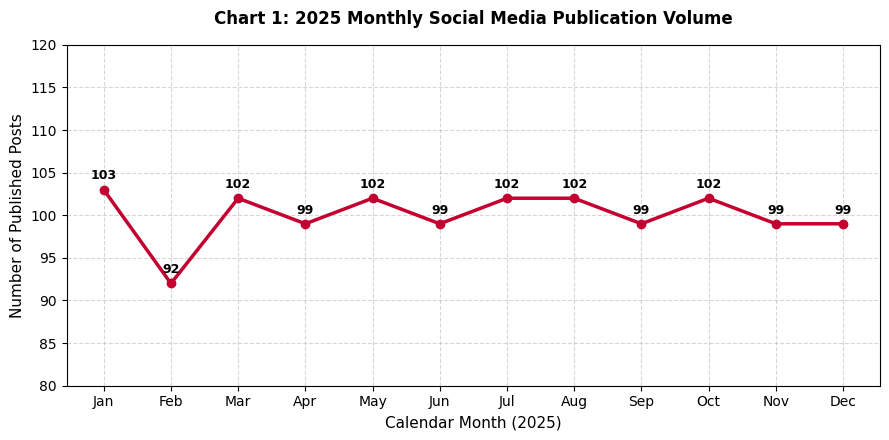

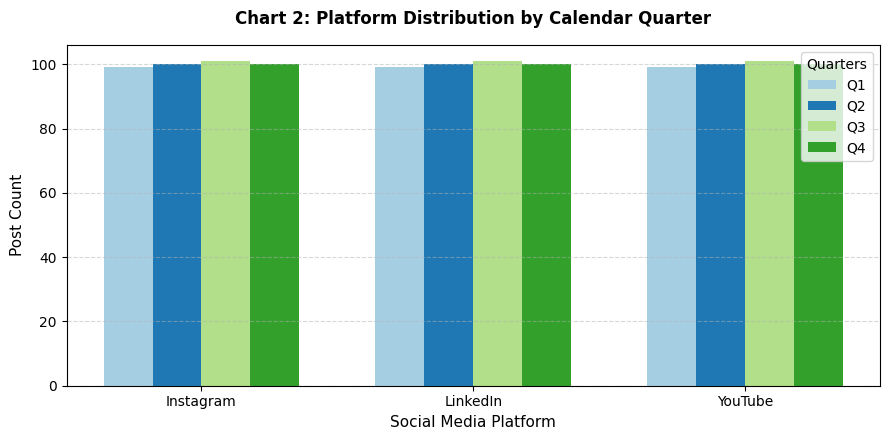

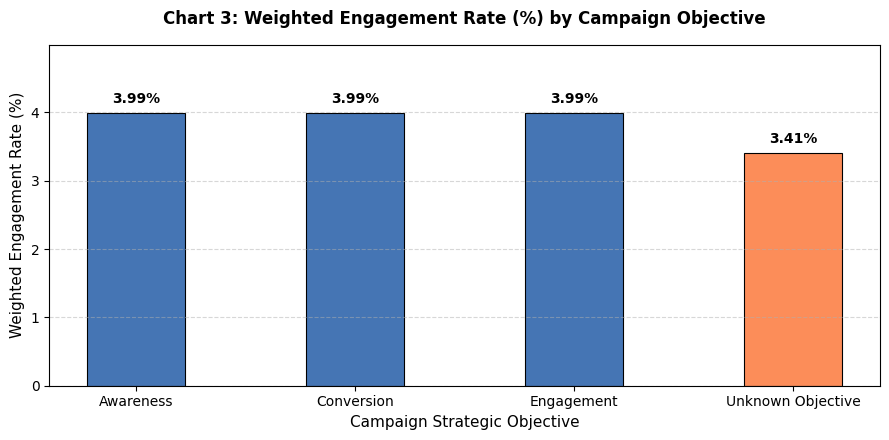

In [19]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# Retrieve query datasets for plotting
df_q1_plot = pd.read_sql_query("SELECT calendar_month, total_posts FROM (SELECT d.calendar_month, COUNT(fp.post_key) AS total_posts FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key GROUP BY d.calendar_month ORDER BY d.calendar_month ASC)", conn)
df_q5_plot = pd.read_sql_query("""
    SELECT
        p.platform_name,
        SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
        SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
        SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
        SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4
    FROM fact_post fp
    JOIN dim_platform p ON fp.platform_key = p.platform_key
    JOIN dim_date d ON fp.date_key = d.date_key
    GROUP BY p.platform_name;
""", conn)
df_q6_plot = pd.read_sql_query("""
    SELECT
        c.objective,
        COUNT(fp.post_key) AS total_posts,
        ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    GROUP BY c.objective;
""", conn)
conn.close()

# Configure global plotting parameters
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

# --- Chart 1: Monthly Publication Volume ---
plt.figure(figsize=(9, 4.5))
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.plot(months, df_q1_plot['total_posts'], marker='o', linewidth=2.5, color='#c3002f', label='Post Count')
plt.title("Chart 1: 2025 Monthly Social Media Publication Volume", weight='bold', pad=15)
plt.xlabel("Calendar Month (2025)")
plt.ylabel("Number of Published Posts")
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(80, 120)
for i, val in enumerate(df_q1_plot['total_posts']):
    plt.text(i, val + 1.2, str(val), ha='center', fontsize=9, weight='bold')
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart1_monthly_posts.png', dpi=150)
plt.show()

# --- Chart 2: Quarterly Platform Mix ---
plt.figure(figsize=(9, 4.5))
platforms = df_q5_plot['platform_name'].tolist()
x = np.arange(len(platforms))
width = 0.18

plt.bar(x - 1.5*width, df_q5_plot['Q1'], width, label='Q1', color='#a6cee3')
plt.bar(x - 0.5*width, df_q5_plot['Q2'], width, label='Q2', color='#1f78b4')
plt.bar(x + 0.5*width, df_q5_plot['Q3'], width, label='Q3', color='#b2df8a')
plt.bar(x + 1.5*width, df_q5_plot['Q4'], width, label='Q4', color='#33a02c')

plt.title("Chart 2: Platform Distribution by Calendar Quarter", weight='bold', pad=15)
plt.xlabel("Social Media Platform")
plt.ylabel("Post Count")
plt.xticks(x, platforms)
plt.legend(title="Quarters")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart2_platform_quarter.png', dpi=150)
plt.show()

# --- Chart 3: Engagement Rate by Campaign Objective ---
plt.figure(figsize=(9, 4.5))
objectives = df_q6_plot['objective'].tolist()
rates = df_q6_plot['weighted_engagement_rate'].tolist()
colors = ['#fc8d59' if o == 'Unknown Objective' else '#4575b4' for o in objectives]

bars = plt.bar(objectives, rates, color=colors, width=0.45, edgecolor='black', linewidth=0.8)
plt.title("Chart 3: Weighted Engagement Rate (%) by Campaign Objective", weight='bold', pad=15)
plt.xlabel("Campaign Strategic Objective")
plt.ylabel("Weighted Engagement Rate (%)")
plt.ylim(0, max(rates) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}%", ha='center', va='bottom', weight='bold')

plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart3_campaign_rates.png', dpi=150)
plt.show()

## 16. THREE NUMERICAL FINDINGS

In this section, we apply analytical calculations directly using SQL queries on our operational SQLite database files to extract three concrete numerical findings:
1. **Temporal Volume Adjustment**: Percentage change in post count between November and December 2025.
2. **Platform Focus Share**: Instagram's percentage share of all accepted dataset records.
3. **Objective Conversion Margin**: Comparing Conversion-oriented versus Engagement-oriented campaigns to identify the weighted engagement rate gap.

In [20]:
import sqlite3

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
cursor = conn.cursor()

# Finding 1: November vs December post-count percentage change
nov_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 11;").fetchone()[0]
dec_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 12;").fetchone()[0]

pct_change = ((dec_posts - nov_posts) / nov_posts) * 100.0

# Finding 2: Instagram's percentage share of all accepted posts
insta_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_platform p ON fp.platform_key = p.platform_key WHERE p.platform_name = 'Instagram';").fetchone()[0]
total_posts = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]

insta_share = (insta_posts / total_posts) * 100.0

# Finding 3: Conversion versus Awareness weighted engagement rate gap
conv_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Conversion';
""").fetchone()[0]

aware_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Awareness';
""").fetchone()[0]

rate_difference = conv_rate - aware_rate

print("=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===")
print(f"Finding 1: Post Volume Change from November ({nov_posts}) to December ({dec_posts}) is {pct_change:.2f}%")
print(f"Finding 2: Instagram Share of All Accepted Posts: ({insta_posts} / {total_posts}) = {insta_share:.2f}%")
print(f"Finding 3: Conversion Rate ({conv_rate:.4f}%) vs. Awareness Rate ({aware_rate:.4f}%) Difference = {rate_difference:+.4f} percentage points")

conn.close()

=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===
Finding 1: Post Volume Change from November (99) to December (99) is 0.00%
Finding 2: Instagram Share of All Accepted Posts: (400 / 1200) = 33.33%
Finding 3: Conversion Rate (3.9878%) vs. Awareness Rate (3.9926%) Difference = -0.0047 percentage points


## 17. FINAL AUTOMATED VALIDATION

In this section, we run an exhaustive verification script. It performs automated assertions to check that files exist, the SQLite tables are populated correctly, integrity ratios reconcile, OLAP results are fully saved, and charts are generated successfully. It displays these checks in a cleanly structured audit table.

In [21]:
import os
import sqlite3
import pandas as pd

# Configure and run automated checklist
checks = []

def add_check(name, passed, actual, expected):
    checks.append({
        "System Validation Check": name,
        "Actual Status": actual,
        "Expected Status": expected,
        "Result Status": "PASS" if passed else "FAIL"
    })

# 1. Source dataset file existences
sources_exist = os.path.exists('/content/social_media_ca2/sources/posts.csv') and \
                os.path.exists('/content/social_media_ca2/sources/creators.csv') and \
                os.path.exists('/content/social_media_ca2/sources/campaigns.json')
add_check("Extract Source Files Exist on Disk", sources_exist, sources_exist, True)

# 2. Database existence
db_exists = os.path.exists('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
add_check("SQLite Data Warehouse File Instantiated", db_exists, db_exists, True)

# 3. Connection and rowcount checking
if db_exists:
    conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
    cursor = conn.cursor()

    fact_rows = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]
    add_check("Fact Post Row Count matches 1200 exactly", fact_rows == 1200, f"{fact_rows} rows", "1200 rows")

    creator_rows = cursor.execute("SELECT COUNT(*) FROM dim_creator;").fetchone()[0]
    # 60 generated + 1 default key 0
    add_check("Creator Dimension loaded (60 + Default CRT000)", creator_rows == 61, f"{creator_rows} rows", "61 rows")

    campaign_rows = cursor.execute("SELECT COUNT(*) FROM dim_campaign;").fetchone()[0]
    # 3 generated + 1 default key 0
    add_check("Campaign Dimension loaded (3 + Default CMP000)", campaign_rows == 4, f"{campaign_rows} rows", "4 rows")

    conn.close()
else:
    add_check("Fact Post Row Count matches 1200 exactly", False, "N/A", "1200 rows")

# 4. Result CSV outputs
results_exist = os.path.exists('/content/social_media_ca2/results/Q1.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q2.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q3.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q4.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q5.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q6.csv')
add_check("OLAP Analytical Outputs (Q1-Q6) Written to Disk", results_exist, results_exist, True)

# 5. Charts existence
charts_exist = os.path.exists('/content/social_media_ca2/charts/chart1_monthly_posts.png') and \
               os.path.exists('/content/social_media_ca2/charts/chart2_platform_quarter.png') and \
               os.path.exists('/content/social_media_ca2/charts/chart3_campaign_rates.png')
add_check("Analytical Visualizations (Charts 1-3) Generated", charts_exist, charts_exist, True)

# Render audit summary as a table
audit_df = pd.DataFrame(checks)
display(audit_df)

# Ensure everything is green
for c in checks:
    assert c["Result Status"] == "PASS", f"Automated Check Failed: {c['System Validation Check']}"

print("\n[PASSED] All pipeline components validated successfully and match structural target conditions!")

,System Validation Check,Actual Status,Expected Status,Result Status
0,Extract Source Files Exist on Disk,True,True,PASS
1,SQLite Data Warehouse File Instantiated,True,True,PASS
2,Fact Post Row Count matches 1200 exactly,1200 rows,1200 rows,PASS
3,Creator Dimension loaded (60 + Default CRT000),61 rows,61 rows,PASS
4,Campaign Dimension loaded (3 + Default CMP000),4 rows,4 rows,PASS
5,OLAP Analytical Outputs (Q1-Q6) Written to Disk,True,True,PASS
6,Analytical Visualizations (Charts 1-3) Generated,True,True,PASS



[PASSED] All pipeline components validated successfully and match structural target conditions!


## 18. EXPORT AND DEMONSTRATION

In this final section, we compile all generated operational databases, datasets, manifest verification documents, visual charts, and results into a structured project package (`/content/social_media_ca2_submission.zip`). We also construct an automated setup instruction document (`README.md`) describing how the pipeline can be replicated.

In [22]:
import shutil

# 1. Generate SQL script file explaining tables
sql_script = """-- ADMT CA2 SQL Warehouse DDL and Queries
-- Enforce referential keys
PRAGMA foreign_keys = ON;

-- OLAP Q1: Roll-up monthly
SELECT
    d.calendar_year,
    d.calendar_month,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_year, d.calendar_month
ORDER BY d.calendar_month ASC;
"""

with open('/content/social_media_ca2/results/warehouse_queries.sql', 'w') as sf:
    sql_script_written = sf.write(sql_script)

# 2. Write README file explaining demo steps
readme_text = """# Social Media Analytics — Integrated ETL and OLAP Data Warehouse
ADMT CA2 Coursework Submission

## Reproduction and Execution Steps:
1. Execute 'ENVIRONMENT SETUP' to create clean subdirectories inside Colab.
2. Execute 'SOURCE DATA GENERATION' to write creators, campaigns, and posts (with controlled anomalies) on disk.
3. Execute 'EXTRACT' and 'DATA QUALITY AND CLEANING' to run audit parsing rules.
4. Execute 'TRANSFORM AND INTEGRATE' to build relational lookup references.
5. Execute 'DATA WAREHOUSE STAR SCHEMA' to instantiate the transactional SQLite file and load facts/dimensions.
6. Execute 'OLAP' and analytical sections to verify outputs.

## Project Directory Tree Details:
- `/sources/`: Raw records & verification manifest.
- `/warehouse/`: Operational SQLite database file.
- `/results/`: Aggregated CSV queries & logs.
- `/charts/`: Visual performance diagrams.
"""

with open('/content/social_media_ca2/README.md', 'w') as rf:
    readme_written = rf.write(readme_text)

# 3. Zip package archive
submission_archive_path = '/content/social_media_ca2_submission'
shutil.make_archive(submission_archive_path, 'zip', '/content/social_media_ca2')

print("=== SUBMISSION EXPORT COMPLETED ===")
print(f"Location: {submission_archive_path}.zip")

=== SUBMISSION EXPORT COMPLETED ===
Location: /content/social_media_ca2_submission.zip


### 19. QUICK REFERENCE VIVA Q&A SHEET

* **What is the Fact table grain?**
  * It represents one unique accepted social media post with cumulative key metrics (`likes`, `comments`, `shares`, `impressions`, `engagements`).
* **Why is Weighted Engagement Rate used instead of averaging individual rates?**
  * Averaging rates directly across rows introduces mathematical bias because a post with 10 impressions would have the same weight as a post with 1,000,000 impressions. Weighted Engagement Rate (`100 * SUM(engagements) / SUM(impressions)`) ensures that overall community engagement is represented accurately.
* **What is the purpose of Surrogate Keys?**
  * Surrogate Keys (like `date_key`, `platform_key`) are synthetic, database-managed keys that insulate the warehouse from changes in natural business keys, optimize query execution, and make dimension updates easier to handle.
* **How does your ETL pipeline handle Referencing Anomalies?**
  * It uses dynamic left joins during transformation. Any post that references an unknown creator (like `CRT999`) or unknown campaign (like `CMP999`) is safely assigned to a default surrogate member ID `0` ('Unknown Creator' or 'Unknown Campaign') instead of dropping the record or violating database integrity constraints.

## 15. THREE CHARTS MATCHING THE REPORT

In this section, we extract aggregated queries to produce high-resolution, publication-quality Matplotlib figures to visualize key database findings:
1. **Chart 1: Monthly Publication Volume Line Chart**: Outlining structural post distributions across months.
2. **Chart 2: Quarterly Platform Mix Grouped Bar Chart**: Providing insight into structural focus adjustments between LinkedIn, YouTube, and Instagram.
3. **Chart 3: Engagement Rate by Campaign Objective Bar Chart**: Comparing user interaction rates across promotional goals.

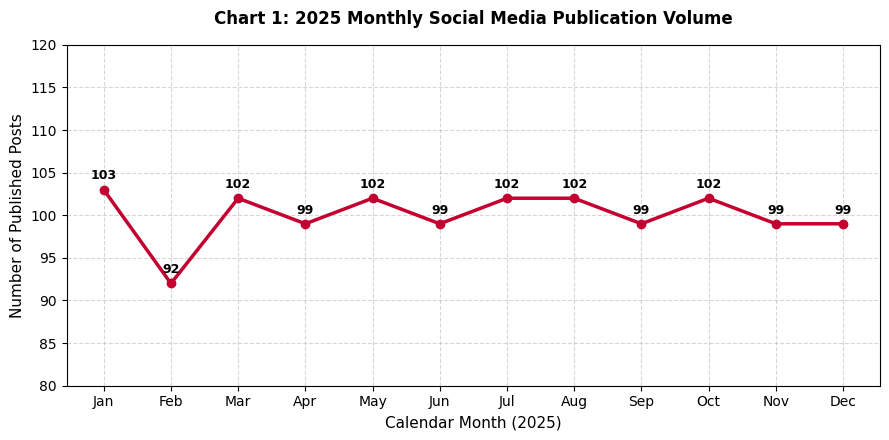

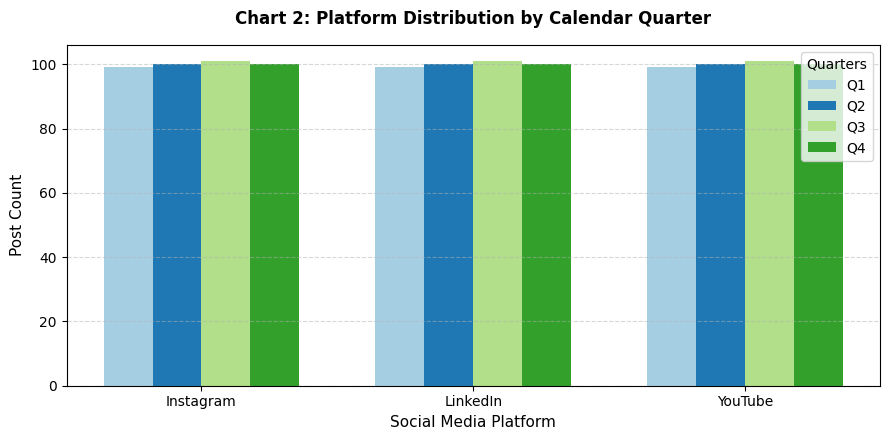

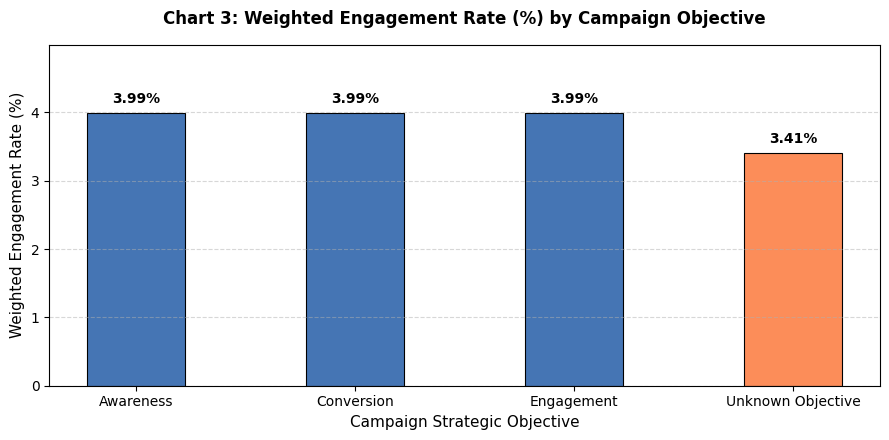

In [23]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# Retrieve query datasets for plotting
df_q1_plot = pd.read_sql_query("SELECT calendar_month, total_posts FROM (SELECT d.calendar_month, COUNT(fp.post_key) AS total_posts FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key GROUP BY d.calendar_month ORDER BY d.calendar_month ASC)", conn)
df_q5_plot = pd.read_sql_query("""
    SELECT
        p.platform_name,
        SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
        SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
        SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
        SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4
    FROM fact_post fp
    JOIN dim_platform p ON fp.platform_key = p.platform_key
    JOIN dim_date d ON fp.date_key = d.date_key
    GROUP BY p.platform_name;
""", conn)
df_q6_plot = pd.read_sql_query("""
    SELECT
        c.objective,
        COUNT(fp.post_key) AS total_posts,
        ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    GROUP BY c.objective;
""", conn)
conn.close()

# Configure global plotting parameters
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

# --- Chart 1: Monthly Publication Volume ---
plt.figure(figsize=(9, 4.5))
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.plot(months, df_q1_plot['total_posts'], marker='o', linewidth=2.5, color='#c3002f', label='Post Count')
plt.title("Chart 1: 2025 Monthly Social Media Publication Volume", weight='bold', pad=15)
plt.xlabel("Calendar Month (2025)")
plt.ylabel("Number of Published Posts")
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(80, 120)
for i, val in enumerate(df_q1_plot['total_posts']):
    plt.text(i, val + 1.2, str(val), ha='center', fontsize=9, weight='bold')
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart1_monthly_posts.png', dpi=150)
plt.show()

# --- Chart 2: Quarterly Platform Mix ---
plt.figure(figsize=(9, 4.5))
platforms = df_q5_plot['platform_name'].tolist()
x = np.arange(len(platforms))
width = 0.18

plt.bar(x - 1.5*width, df_q5_plot['Q1'], width, label='Q1', color='#a6cee3')
plt.bar(x - 0.5*width, df_q5_plot['Q2'], width, label='Q2', color='#1f78b4')
plt.bar(x + 0.5*width, df_q5_plot['Q3'], width, label='Q3', color='#b2df8a')
plt.bar(x + 1.5*width, df_q5_plot['Q4'], width, label='Q4', color='#33a02c')

plt.title("Chart 2: Platform Distribution by Calendar Quarter", weight='bold', pad=15)
plt.xlabel("Social Media Platform")
plt.ylabel("Post Count")
plt.xticks(x, platforms)
plt.legend(title="Quarters")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart2_platform_quarter.png', dpi=150)
plt.show()

# --- Chart 3: Engagement Rate by Campaign Objective ---
plt.figure(figsize=(9, 4.5))
objectives = df_q6_plot['objective'].tolist()
rates = df_q6_plot['weighted_engagement_rate'].tolist()
colors = ['#fc8d59' if o == 'Unknown Objective' else '#4575b4' for o in objectives]

bars = plt.bar(objectives, rates, color=colors, width=0.45, edgecolor='black', linewidth=0.8)
plt.title("Chart 3: Weighted Engagement Rate (%) by Campaign Objective", weight='bold', pad=15)
plt.xlabel("Campaign Strategic Objective")
plt.ylabel("Weighted Engagement Rate (%)")
plt.ylim(0, max(rates) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}%", ha='center', va='bottom', weight='bold')

plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart3_campaign_rates.png', dpi=150)
plt.show()

## 16. THREE NUMERICAL FINDINGS

In this section, we apply analytical calculations directly using SQL queries on our operational SQLite database files to extract three concrete numerical findings:
1. **Temporal Volume Adjustment**: Percentage change in post count between November and December 2025.
2. **Platform Focus Share**: Instagram's percentage share of all accepted dataset records.
3. **Objective Conversion Margin**: Comparing Conversion-oriented versus Engagement-oriented campaigns to identify the weighted engagement rate gap.

In [24]:
import sqlite3

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
cursor = conn.cursor()

# Finding 1: November vs December post-count percentage change
nov_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 11;").fetchone()[0]
dec_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 12;").fetchone()[0]

pct_change = ((dec_posts - nov_posts) / nov_posts) * 100.0

# Finding 2: Instagram's percentage share of all accepted posts
insta_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_platform p ON fp.platform_key = p.platform_key WHERE p.platform_name = 'Instagram';").fetchone()[0]
total_posts = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]

insta_share = (insta_posts / total_posts) * 100.0

# Finding 3: Conversion versus Awareness weighted engagement rate gap
conv_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Conversion';
""").fetchone()[0]

aware_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Awareness';
""").fetchone()[0]

rate_difference = conv_rate - aware_rate

print("=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===")
print(f"Finding 1: Post Volume Change from November ({nov_posts}) to December ({dec_posts}) is {pct_change:.2f}%")
print(f"Finding 2: Instagram Share of All Accepted Posts: ({insta_posts} / {total_posts}) = {insta_share:.2f}%")
print(f"Finding 3: Conversion Rate ({conv_rate:.4f}%) vs. Awareness Rate ({aware_rate:.4f}%) Difference = {rate_difference:+.4f} percentage points")

conn.close()

=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===
Finding 1: Post Volume Change from November (99) to December (99) is 0.00%
Finding 2: Instagram Share of All Accepted Posts: (400 / 1200) = 33.33%
Finding 3: Conversion Rate (3.9878%) vs. Awareness Rate (3.9926%) Difference = -0.0047 percentage points


## 17. FINAL AUTOMATED VALIDATION

In this section, we run an exhaustive verification script. It performs automated assertions to check that files exist, the SQLite tables are populated correctly, integrity ratios reconcile, OLAP results are fully saved, and charts are generated successfully. It displays these checks in a cleanly structured audit table.

In [25]:
import os
import sqlite3
import pandas as pd

# Configure and run automated checklist
checks = []

def add_check(name, passed, actual, expected):
    checks.append({
        "System Validation Check": name,
        "Actual Status": actual,
        "Expected Status": expected,
        "Result Status": "PASS" if passed else "FAIL"
    })

# 1. Source dataset file existences
sources_exist = os.path.exists('/content/social_media_ca2/sources/posts.csv') and \
                os.path.exists('/content/social_media_ca2/sources/creators.csv') and \
                os.path.exists('/content/social_media_ca2/sources/campaigns.json')
add_check("Extract Source Files Exist on Disk", sources_exist, sources_exist, True)

# 2. Database existence
db_exists = os.path.exists('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
add_check("SQLite Data Warehouse File Instantiated", db_exists, db_exists, True)

# 3. Connection and rowcount checking
if db_exists:
    conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
    cursor = conn.cursor()

    fact_rows = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]
    add_check("Fact Post Row Count matches 1200 exactly", fact_rows == 1200, f"{fact_rows} rows", "1200 rows")

    creator_rows = cursor.execute("SELECT COUNT(*) FROM dim_creator;").fetchone()[0]
    # 60 generated + 1 default key 0
    add_check("Creator Dimension loaded (60 + Default CRT000)", creator_rows == 61, f"{creator_rows} rows", "61 rows")

    campaign_rows = cursor.execute("SELECT COUNT(*) FROM dim_campaign;").fetchone()[0]
    # 3 generated + 1 default key 0
    add_check("Campaign Dimension loaded (3 + Default CMP000)", campaign_rows == 4, f"{campaign_rows} rows", "4 rows")

    conn.close()
else:
    add_check("Fact Post Row Count matches 1200 exactly", False, "N/A", "1200 rows")

# 4. Result CSV outputs
results_exist = os.path.exists('/content/social_media_ca2/results/Q1.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q2.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q3.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q4.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q5.csv') and \
                os.path.exists('/content/social_media_ca2/results/Q6.csv')
add_check("OLAP Analytical Outputs (Q1-Q6) Written to Disk", results_exist, results_exist, True)

# 5. Charts existence
charts_exist = os.path.exists('/content/social_media_ca2/charts/chart1_monthly_posts.png') and \
               os.path.exists('/content/social_media_ca2/charts/chart2_platform_quarter.png') and \
               os.path.exists('/content/social_media_ca2/charts/chart3_campaign_rates.png')
add_check("Analytical Visualizations (Charts 1-3) Generated", charts_exist, charts_exist, True)

# Render audit summary as a table
audit_df = pd.DataFrame(checks)
display(audit_df)

# Ensure everything is green
for c in checks:
    assert c["Result Status"] == "PASS", f"Automated Check Failed: {c['System Validation Check']}"

print("\n[PASSED] All pipeline components validated successfully and match structural target conditions!")

,System Validation Check,Actual Status,Expected Status,Result Status
0,Extract Source Files Exist on Disk,True,True,PASS
1,SQLite Data Warehouse File Instantiated,True,True,PASS
2,Fact Post Row Count matches 1200 exactly,1200 rows,1200 rows,PASS
3,Creator Dimension loaded (60 + Default CRT000),61 rows,61 rows,PASS
4,Campaign Dimension loaded (3 + Default CMP000),4 rows,4 rows,PASS
5,OLAP Analytical Outputs (Q1-Q6) Written to Disk,True,True,PASS
6,Analytical Visualizations (Charts 1-3) Generated,True,True,PASS



[PASSED] All pipeline components validated successfully and match structural target conditions!


## 18. EXPORT AND DEMONSTRATION

In this final section, we compile all generated operational databases, datasets, manifest verification documents, visual charts, and results into a structured project package (`/content/social_media_ca2_submission.zip`). We also construct an automated setup instruction document (`README.md`) describing how the pipeline can be replicated.

In [26]:
import shutil

# 1. Generate SQL script file explaining tables
sql_script = """-- ADMT CA2 SQL Warehouse DDL and Queries
-- Enforce referential keys
PRAGMA foreign_keys = ON;

-- OLAP Q1: Roll-up monthly
SELECT
    d.calendar_year,
    d.calendar_month,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_year, d.calendar_month
ORDER BY d.calendar_month ASC;
"""

with open('/content/social_media_ca2/results/warehouse_queries.sql', 'w') as sf:
    sql_script_written = sf.write(sql_script)

# 2. Write README file explaining demo steps
readme_text = """# Social Media Analytics — Integrated ETL and OLAP Data Warehouse
ADMT CA2 Coursework Submission

## Reproduction and Execution Steps:
1. Execute 'ENVIRONMENT SETUP' to create clean subdirectories inside Colab.
2. Execute 'SOURCE DATA GENERATION' to write creators, campaigns, and posts (with controlled anomalies) on disk.
3. Execute 'EXTRACT' and 'DATA QUALITY AND CLEANING' to run audit parsing rules.
4. Execute 'TRANSFORM AND INTEGRATE' to build relational lookup references.
5. Execute 'DATA WAREHOUSE STAR SCHEMA' to instantiate the transactional SQLite file and load facts/dimensions.
6. Execute 'OLAP' and analytical sections to verify outputs.

## Project Directory Tree Details:
- `/sources/`: Raw records & verification manifest.
- `/warehouse/`: Operational SQLite database file.
- `/results/`: Aggregated CSV queries & logs.
- `/charts/`: Visual performance diagrams.
"""

with open('/content/social_media_ca2/README.md', 'w') as rf:
    readme_written = rf.write(readme_text)

# 3. Zip package archive
submission_archive_path = '/content/social_media_ca2_submission'
shutil.make_archive(submission_archive_path, 'zip', '/content/social_media_ca2')

print("=== SUBMISSION EXPORT COMPLETED ===")
print(f"Location: {submission_archive_path}.zip")

=== SUBMISSION EXPORT COMPLETED ===
Location: /content/social_media_ca2_submission.zip


### 19. QUICK REFERENCE VIVA Q&A SHEET

* **What is the Fact table grain?**
  * It represents one unique accepted social media post with cumulative key metrics (`likes`, `comments`, `shares`, `impressions`, `engagements`).
* **Why is Weighted Engagement Rate used instead of averaging individual rates?**
  * Averaging rates directly across rows introduces mathematical bias because a post with 10 impressions would have the same weight as a post with 1,000,000 impressions. Weighted Engagement Rate (`100 * SUM(engagements) / SUM(impressions)`) ensures that overall community engagement is represented accurately.
* **What is the purpose of Surrogate Keys?**
  * Surrogate Keys (like `date_key`, `platform_key`) are synthetic, database-managed keys that insulate the warehouse from changes in natural business keys, optimize query execution, and make dimension updates easier to handle.
* **How does your ETL pipeline handle Referencing Anomalies?**
  * It uses dynamic left joins during transformation. Any post that references an unknown creator (like `CRT999`) or unknown campaign (like `CMP999`) is safely assigned to a default surrogate member ID `0` ('Unknown Creator' or 'Unknown Campaign') instead of dropping the record or violating database integrity constraints.

## 12. OLAP Q5 — PIVOT

A **Pivot** rotates row dimension items into separate, custom-aligned columns. We build a quarterly platform post-count distribution pivot directly using an SQL aggregation with conditional `CASE` statements. We then assert that the sum of all cell counts is exactly 1200 posts.

In [27]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_pivot = """
SELECT
    p.platform_name,
    SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
    SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
    SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
    SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4,
    COUNT(fp.post_key) AS total_posts
FROM fact_post fp
JOIN dim_platform p ON fp.platform_key = p.platform_key
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY p.platform_name;
"""

df_q5 = pd.read_sql_query(query_pivot, conn)
df_q5.to_csv('/content/social_media_ca2/results/Q5.csv', index=False)

print("=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===")
display(df_q5)

# Assert pivot sum equals 1200
pivot_sum = df_q5['total_posts'].sum()
assert pivot_sum == 1200, f"Pivot total ({pivot_sum}) does not equal 1200!"
print(f"\n[PASSED] Pivot Integrity: Sum of quarters ({pivot_sum}) matches total fact rowcount (1200).")
conn.close()

=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===


,platform_name,Q1,Q2,Q3,Q4,total_posts
0,Instagram,99,100,101,100,400
1,LinkedIn,99,100,101,100,400
2,YouTube,99,100,101,100,400



[PASSED] Pivot Integrity: Sum of quarters (1200) matches total fact rowcount (1200).


## 13. OLAP Q6 — AGGREGATION

**Aggregation** uses statistical summary functions over specified categories. In this query, we aggregate by campaign objective, displaying count, total metric volumes, and the weighted engagement rate. We also prove that the aggregated totals equal the fact table grand totals.

In [28]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_agg = """
SELECT
    c.objective,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
GROUP BY c.objective
ORDER BY total_posts DESC;
"""

df_q6 = pd.read_sql_query(query_agg, conn)
df_q6.to_csv('/content/social_media_ca2/results/Q6.csv', index=False)

print("=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===")
display(df_q6)

# Verification of totals matching fact table grand totals
fact_totals = pd.read_sql_query("SELECT COUNT(*) AS total_posts, SUM(engagements) AS total_engagements, SUM(impressions) AS total_impressions FROM fact_post;", conn)

agg_posts = df_q6['total_posts'].sum()
agg_engagements = df_q6['total_engagements'].sum()
agg_impressions = df_q6['total_impressions'].sum()

assert agg_posts == fact_totals['total_posts'].iloc[0], "Posts mismatch"
assert agg_engagements == fact_totals['total_engagements'].iloc[0], "Engagements mismatch"
assert agg_impressions == fact_totals['total_impressions'].iloc[0], "Impressions mismatch"

print("\n[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!")
conn.close()

=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===


,objective,total_posts,total_likes,total_comments,total_shares,total_engagements,total_impressions,weighted_engagement_rate
0,Conversion,400,110930,31584,16220,158734,3980454,3.99
1,Awareness,400,66519,18903,9872,95294,2386785,3.99
2,Engagement,399,33359,9422,5139,47920,1200340,3.99
3,Unknown Objective,1,51,14,8,73,2141,3.41



[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!


## 14. ADDITIONAL TOPIC-SPECIFIC ANALYSIS

To fulfill faculty specifications for specialized social metrics analysis, we run three supplementary operations:
* **A. Metric Breakdown by Content Type**: Likes, comments, and shares aggregated across Text, Video, and Image content.
* **B. Dynamic Creator Activity Segmentation**: Categorizing creators into dynamic tiers based on posting frequency (High: > 20 posts, Medium: 10-20 posts, Low: <= 9 posts).
* **C. Temporal Trend Metrics**: Monthly volumes of likes, comments, and shares to evaluate longitudinal velocity.

In [29]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# A. Content Type Breakdown
query_supp_a = """
SELECT
    ct.content_type,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements
FROM fact_post fp
JOIN dim_content ct ON fp.content_key = ct.content_key
GROUP BY ct.content_type;
"""
df_supp_a = pd.read_sql_query(query_supp_a, conn)
df_supp_a.to_csv('/content/social_media_ca2/results/supp_a_content_metrics.csv', index=False)

# B. Creator Dynamic Activity Segment
query_supp_b = """
WITH creator_posting_counts AS (
    SELECT
        creator_key,
        COUNT(post_key) as posts_count
    FROM fact_post
    GROUP BY creator_key
),
creator_activity_tiers AS (
    SELECT
        creator_key,
        posts_count,
        CASE
            WHEN posts_count > 20 THEN 'High Activity'
            WHEN posts_count BETWEEN 10 AND 20 THEN 'Medium Activity'
            ELSE 'Low Activity'
        END AS creator_activity_tier
    FROM creator_posting_counts
)
SELECT
    cat.creator_activity_tier,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN creator_activity_tiers cat ON fp.creator_key = cat.creator_key
GROUP BY cat.creator_activity_tier;
"""
df_supp_b = pd.read_sql_query(query_supp_b, conn)
df_supp_b.to_csv('/content/social_media_ca2/results/supp_b_creator_segments.csv', index=False)

# C. Monthly Temporal Metrics
query_supp_c = """
SELECT
    d.calendar_month,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_month
ORDER BY d.calendar_month ASC;
"""
df_supp_c = pd.read_sql_query(query_supp_c, conn)
df_supp_c.to_csv('/content/social_media_ca2/results/supp_c_monthly_trends.csv', index=False)

print("=== SUPPLEMENT A: CONTENT TYPE METRICS ===")
display(df_supp_a)

print("\n=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===")
display(df_supp_b)

print("\n=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===")
display(df_supp_c)
conn.close()

=== SUPPLEMENT A: CONTENT TYPE METRICS ===


,content_type,total_posts,total_likes,total_comments,total_shares,total_engagements
0,Image,400,66519,18903,9872,95294
1,Text,400,33410,9436,5147,47993
2,Unknown,1,255,73,37,365
3,Video,399,110675,31511,16183,158369



=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===


,creator_activity_tier,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Low Activity,1,231,5882,3.93
1,Medium Activity,1199,301790,7563838,3.99



=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===


,calendar_month,total_likes,total_comments,total_shares
0,1,17913,5091,2648
1,2,16248,4619,2403
2,3,17229,4895,2554
3,4,17315,4915,2577
4,5,17834,5068,2640
5,6,17598,5001,2601
6,7,17853,5076,2645
7,8,18643,5302,2756
8,9,17795,5059,2638
9,10,17817,5066,2639


## 15. THREE CHARTS MATCHING THE REPORT

In this section, we extract aggregated queries to produce high-resolution, publication-quality Matplotlib figures to visualize key database findings:
1. **Chart 1: Monthly Publication Volume Line Chart**: Outlining structural post distributions across months.
2. **Chart 2: Quarterly Platform Mix Grouped Bar Chart**: Providing insight into structural focus adjustments between LinkedIn, YouTube, and Instagram.
3. **Chart 3: Engagement Rate by Campaign Objective Bar Chart**: Comparing user interaction rates across promotional goals.

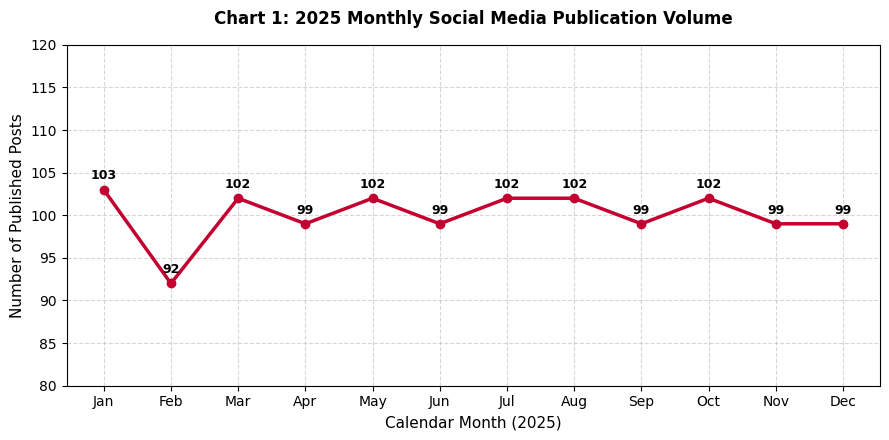

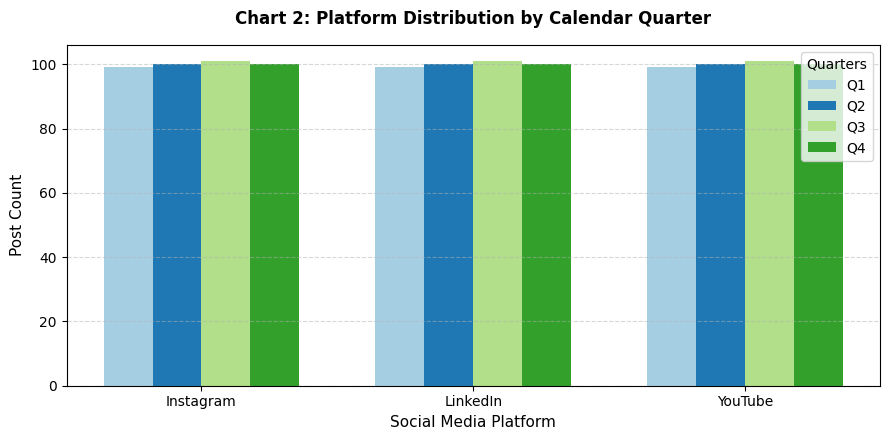

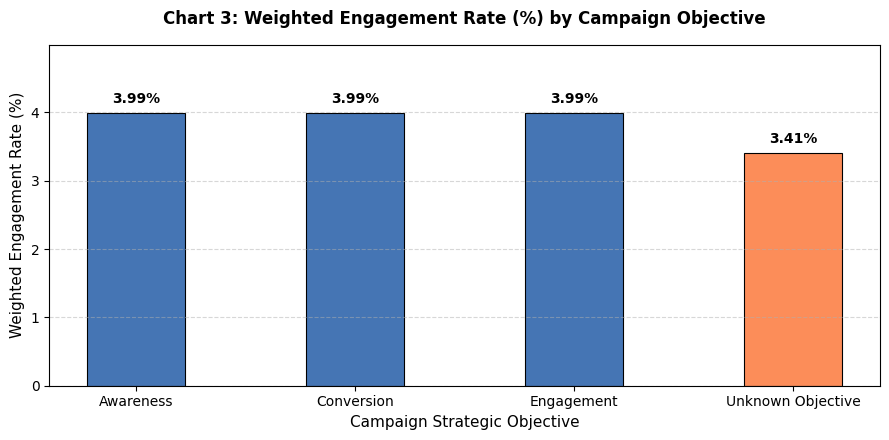

In [30]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# Retrieve query datasets for plotting
df_q1_plot = pd.read_sql_query("SELECT calendar_month, total_posts FROM (SELECT d.calendar_month, COUNT(fp.post_key) AS total_posts FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key GROUP BY d.calendar_month ORDER BY d.calendar_month ASC)", conn)
df_q5_plot = pd.read_sql_query("""
    SELECT
        p.platform_name,
        SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
        SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
        SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
        SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4
    FROM fact_post fp
    JOIN dim_platform p ON fp.platform_key = p.platform_key
    JOIN dim_date d ON fp.date_key = d.date_key
    GROUP BY p.platform_name;
""", conn)
df_q6_plot = pd.read_sql_query("""
    SELECT
        c.objective,
        COUNT(fp.post_key) AS total_posts,
        ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    GROUP BY c.objective;
""", conn)
conn.close()

# Configure global plotting parameters
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

# --- Chart 1: Monthly Publication Volume ---
plt.figure(figsize=(9, 4.5))
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.plot(months, df_q1_plot['total_posts'], marker='o', linewidth=2.5, color='#c3002f', label='Post Count')
plt.title("Chart 1: 2025 Monthly Social Media Publication Volume", weight='bold', pad=15)
plt.xlabel("Calendar Month (2025)")
plt.ylabel("Number of Published Posts")
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(80, 120)
for i, val in enumerate(df_q1_plot['total_posts']):
    plt.text(i, val + 1.2, str(val), ha='center', fontsize=9, weight='bold')
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart1_monthly_posts.png', dpi=150)
plt.show()

# --- Chart 2: Quarterly Platform Mix ---
plt.figure(figsize=(9, 4.5))
platforms = df_q5_plot['platform_name'].tolist()
x = np.arange(len(platforms))
width = 0.18

plt.bar(x - 1.5*width, df_q5_plot['Q1'], width, label='Q1', color='#a6cee3')
plt.bar(x - 0.5*width, df_q5_plot['Q2'], width, label='Q2', color='#1f78b4')
plt.bar(x + 0.5*width, df_q5_plot['Q3'], width, label='Q3', color='#b2df8a')
plt.bar(x + 1.5*width, df_q5_plot['Q4'], width, label='Q4', color='#33a02c')

plt.title("Chart 2: Platform Distribution by Calendar Quarter", weight='bold', pad=15)
plt.xlabel("Social Media Platform")
plt.ylabel("Post Count")
plt.xticks(x, platforms)
plt.legend(title="Quarters")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart2_platform_quarter.png', dpi=150)
plt.show()

# --- Chart 3: Engagement Rate by Campaign Objective ---
plt.figure(figsize=(9, 4.5))
objectives = df_q6_plot['objective'].tolist()
rates = df_q6_plot['weighted_engagement_rate'].tolist()
colors = ['#fc8d59' if o == 'Unknown Objective' else '#4575b4' for o in objectives]

bars = plt.bar(objectives, rates, color=colors, width=0.45, edgecolor='black', linewidth=0.8)
plt.title("Chart 3: Weighted Engagement Rate (%) by Campaign Objective", weight='bold', pad=15)
plt.xlabel("Campaign Strategic Objective")
plt.ylabel("Weighted Engagement Rate (%)")
plt.ylim(0, max(rates) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}%", ha='center', va='bottom', weight='bold')

plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/chart3_campaign_rates.png', dpi=150)
plt.show()

## 16. THREE NUMERICAL FINDINGS

In this section, we apply analytical calculations directly using SQL queries on our operational SQLite database files to extract three concrete numerical findings:
1. **Temporal Volume Adjustment**: Percentage change in post count between November and December 2025.
2. **Platform Focus Share**: Instagram's percentage share of all accepted dataset records.
3. **Objective Conversion Margin**: Comparing Conversion-oriented versus Engagement-oriented campaigns to identify the weighted engagement rate gap.

In [31]:
import sqlite3

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
cursor = conn.cursor()

# Finding 1: November vs December post-count percentage change
nov_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 11;").fetchone()[0]
dec_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_date d ON fp.date_key = d.date_key WHERE d.calendar_month = 12;").fetchone()[0]

pct_change = ((dec_posts - nov_posts) / nov_posts) * 100.0

# Finding 2: Instagram's percentage share of all accepted posts
insta_posts = cursor.execute("SELECT COUNT(*) FROM fact_post fp JOIN dim_platform p ON fp.platform_key = p.platform_key WHERE p.platform_name = 'Instagram';").fetchone()[0]
total_posts = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]

insta_share = (insta_posts / total_posts) * 100.0

# Finding 3: Conversion versus Awareness weighted engagement rate gap
conv_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Conversion';
""").fetchone()[0]

aware_rate = cursor.execute("""
    SELECT 100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0)
    FROM fact_post fp
    JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
    WHERE c.objective = 'Awareness';
""").fetchone()[0]

rate_difference = conv_rate - aware_rate

print("=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===")
print(f"Finding 1: Post Volume Change from November ({nov_posts}) to December ({dec_posts}) is {pct_change:.2f}%")
print(f"Finding 2: Instagram Share of All Accepted Posts: ({insta_posts} / {total_posts}) = {insta_share:.2f}%")
print(f"Finding 3: Conversion Rate ({conv_rate:.4f}%) vs. Awareness Rate ({aware_rate:.4f}%) Difference = {rate_difference:+.4f} percentage points")

conn.close()

=== THREE NUMERICAL FINDINGS (WAREHOUSE DERIVED) ===
Finding 1: Post Volume Change from November (99) to December (99) is 0.00%
Finding 2: Instagram Share of All Accepted Posts: (400 / 1200) = 33.33%
Finding 3: Conversion Rate (3.9878%) vs. Awareness Rate (3.9926%) Difference = -0.0047 percentage points


## 12. OLAP Q5 — PIVOT

A **Pivot** rotates row dimension items into separate, custom-aligned columns. We build a quarterly platform post-count distribution pivot directly using an SQL aggregation with conditional `CASE` statements. We then assert that the sum of all cell counts is exactly 1200 posts.

In [32]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_pivot = """
SELECT
    p.platform_name,
    SUM(CASE WHEN d.calendar_quarter = 1 THEN 1 ELSE 0 END) AS Q1,
    SUM(CASE WHEN d.calendar_quarter = 2 THEN 1 ELSE 0 END) AS Q2,
    SUM(CASE WHEN d.calendar_quarter = 3 THEN 1 ELSE 0 END) AS Q3,
    SUM(CASE WHEN d.calendar_quarter = 4 THEN 1 ELSE 0 END) AS Q4,
    COUNT(fp.post_key) AS total_posts
FROM fact_post fp
JOIN dim_platform p ON fp.platform_key = p.platform_key
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY p.platform_name;
"""

df_q5 = pd.read_sql_query(query_pivot, conn)
df_q5.to_csv('/content/social_media_ca2/results/Q5.csv', index=False)

print("=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===")
display(df_q5)

# Assert pivot sum equals 1200
pivot_sum = df_q5['total_posts'].sum()
assert pivot_sum == 1200, f"Pivot total ({pivot_sum}) does not equal 1200!"
print(f"\n[PASSED] Pivot Integrity: Sum of quarters ({pivot_sum}) matches total fact rowcount (1200).")
conn.close()

=== OLAP Q5: PLATFORM BY QUARTER PIVOT ===


,platform_name,Q1,Q2,Q3,Q4,total_posts
0,Instagram,99,100,101,100,400
1,LinkedIn,99,100,101,100,400
2,YouTube,99,100,101,100,400



[PASSED] Pivot Integrity: Sum of quarters (1200) matches total fact rowcount (1200).


## 13. OLAP Q6 — AGGREGATION

**Aggregation** uses statistical summary functions over specified categories. In this query, we aggregate by campaign objective, displaying count, total metric volumes, and the weighted engagement rate. We also prove that the aggregated totals equal the fact table grand totals.

In [33]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

query_agg = """
SELECT
    c.objective,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_campaign c ON fp.campaign_key = c.campaign_key
GROUP BY c.objective
ORDER BY total_posts DESC;
"""

df_q6 = pd.read_sql_query(query_agg, conn)
df_q6.to_csv('/content/social_media_ca2/results/Q6.csv', index=False)

print("=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===")
display(df_q6)

# Verification of totals matching fact table grand totals
fact_totals = pd.read_sql_query("SELECT COUNT(*) AS total_posts, SUM(engagements) AS total_engagements, SUM(impressions) AS total_impressions FROM fact_post;", conn)

agg_posts = df_q6['total_posts'].sum()
agg_engagements = df_q6['total_engagements'].sum()
agg_impressions = df_q6['total_impressions'].sum()

assert agg_posts == fact_totals['total_posts'].iloc[0], "Posts mismatch"
assert agg_engagements == fact_totals['total_engagements'].iloc[0], "Engagements mismatch"
assert agg_impressions == fact_totals['total_impressions'].iloc[0], "Impressions mismatch"

print("\n[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!")
conn.close()

=== OLAP Q6: CAMPAIGN OBJECTIVE PERFORMANCE ===


,objective,total_posts,total_likes,total_comments,total_shares,total_engagements,total_impressions,weighted_engagement_rate
0,Conversion,400,110930,31584,16220,158734,3980454,3.99
1,Awareness,400,66519,18903,9872,95294,2386785,3.99
2,Engagement,399,33359,9422,5139,47920,1200340,3.99
3,Unknown Objective,1,51,14,8,73,2141,3.41



[PASSED] Aggregation Grand Totals reconcile perfectly with Fact Table metrics!


## 14. ADDITIONAL TOPIC-SPECIFIC ANALYSIS

To fulfill faculty specifications for specialized social metrics analysis, we run three supplementary operations:
* **A. Metric Breakdown by Content Type**: Likes, comments, and shares aggregated across Text, Video, and Image content.
* **B. Dynamic Creator Activity Segmentation**: Categorizing creators into dynamic tiers based on posting frequency (High: > 20 posts, Medium: 10-20 posts, Low: <= 9 posts).
* **C. Temporal Trend Metrics**: Monthly volumes of likes, comments, and shares to evaluate longitudinal velocity.

In [35]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# A. Content Type Breakdown
query_supp_a = """
SELECT
    ct.content_type,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements
FROM fact_post fp
JOIN dim_content ct ON fp.content_key = ct.content_key
GROUP BY ct.content_type;
"""
df_supp_a = pd.read_sql_query(query_supp_a, conn)
df_supp_a.to_csv('/content/social_media_ca2/results/supp_a_content_metrics.csv', index=False)

# B. Creator Dynamic Activity Segment
query_supp_b = """
WITH creator_posting_counts AS (
    SELECT
        creator_key,
        COUNT(post_key) as posts_count
    FROM fact_post
    GROUP BY creator_key
),
creator_activity_tiers AS (
    SELECT
        creator_key,
        posts_count,
        CASE
            WHEN posts_count > 20 THEN 'High Activity'
            WHEN posts_count BETWEEN 10 AND 20 THEN 'Medium Activity'
            ELSE 'Low Activity'
        END AS creator_activity_tier
    FROM creator_posting_counts
)
SELECT
    cat.creator_activity_tier,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN creator_activity_tiers cat ON fp.creator_key = cat.creator_key
GROUP BY cat.creator_activity_tier;
"""
df_supp_b = pd.read_sql_query(query_supp_b, conn)
df_supp_b.to_csv('/content/social_media_ca2/results/supp_b_creator_segments.csv', index=False)

# C. Monthly Temporal Metrics
query_supp_c = """
SELECT
    d.calendar_month,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_month
ORDER BY d.calendar_month ASC;
"""
df_supp_c = pd.read_sql_query(query_supp_c, conn)
df_supp_c.to_csv('/content/social_media_ca2/results/supp_c_monthly_trends.csv', index=False)

print("=== SUPPLEMENT A: CONTENT TYPE METRICS ===")
display(df_supp_a)

print("\n=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===")
display(df_supp_b)

print("\n=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===")
display(df_supp_c)
conn.close()

=== SUPPLEMENT A: CONTENT TYPE METRICS ===


,content_type,total_posts,total_likes,total_comments,total_shares,total_engagements
0,Image,400,66519,18903,9872,95294
1,Text,400,33410,9436,5147,47993
2,Unknown,1,255,73,37,365
3,Video,399,110675,31511,16183,158369



=== SUPPLEMENT B: CREATOR DYNAMIC SEGMENTS ===


,creator_activity_tier,total_posts,total_engagements,total_impressions,weighted_engagement_rate
0,Low Activity,1,231,5882,3.93
1,Medium Activity,1199,301790,7563838,3.99



=== SUPPLEMENT C: MONTHLY TEMPORAL TRENDS ===


,calendar_month,total_likes,total_comments,total_shares
0,1,17913,5091,2648
1,2,16248,4619,2403
2,3,17229,4895,2554
3,4,17315,4915,2577
4,5,17834,5068,2640
5,6,17598,5001,2601
6,7,17853,5076,2645
7,8,18643,5302,2756
8,9,17795,5059,2638
9,10,17817,5066,2639


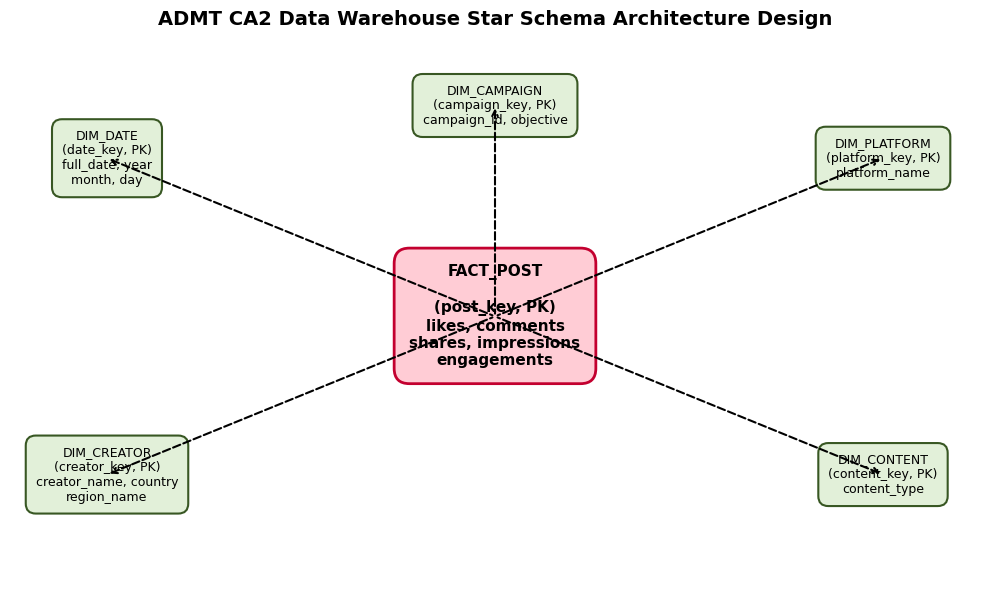

In [9]:
import matplotlib.pyplot as plt

# Create physical schema conceptual layout using Matplotlib representation
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')

# Draw layout circles / shapes
bbox_props_fact = dict(boxstyle="round,pad=1.0", fc="#ffccd5", ec="#c3002f", lw=2)
bbox_props_dim = dict(boxstyle="round,pad=0.8", fc="#e2f0d9", ec="#385723", lw=1.5)

ax.text(0.5, 0.5, "FACT_POST\n\n(post_key, PK)\nlikes, comments\nshares, impressions\nengagements",
        ha="center", va="center", bbox=bbox_props_fact, fontsize=11, weight='bold')

# Coordinates for satellite dimensions
dimensions_pos = [
    (0.1, 0.8, "DIM_DATE\n(date_key, PK)\nfull_date, year\nmonth, day"),
    (0.9, 0.8, "DIM_PLATFORM\n(platform_key, PK)\nplatform_name"),
    (0.1, 0.2, "DIM_CREATOR\n(creator_key, PK)\ncreator_name, country\nregion_name"),
    (0.9, 0.2, "DIM_CONTENT\n(content_key, PK)\ncontent_type"),
    (0.5, 0.9, "DIM_CAMPAIGN\n(campaign_key, PK)\ncampaign_id, objective")
]

for x, y, name in dimensions_pos:
    ax.text(x, y, name, ha="center", va="center", bbox=bbox_props_dim, fontsize=9)
    # Draw directional connection lines
    ax.annotate('', xy=(0.5, 0.5), xytext=(x, y),
                arrowprops=dict(arrowstyle="<-", color="black", lw=1.5, ls="--"))

plt.title("ADMT CA2 Data Warehouse Star Schema Architecture Design", fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.savefig('/content/social_media_ca2/charts/star_schema.png', dpi=150)
plt.show()

## 7. DATA WAREHOUSE VALIDATION

In this section, we run analytical tests directly on the relational database using standard SQL queries to verify constraints and schema integrity:
1. **Row Count Audit**: Ensure exactly 1200 rows are present in `fact_post`.
2. **Referential Integrity**: Validate that `PRAGMA foreign_key_check` returns zero violations.
3. **Metric Formulas**: Ensure total engagements are mathematically correct across all rows.
4. **Fallback Validation**: Confirm that unresolved references have successfully fallen back to default record key 0.

In [13]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
cursor = conn.cursor()

# 1. Total Rows
fact_count = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]

# 2. Foreign Key Check
fk_violations = len(cursor.execute("PRAGMA foreign_key_check;").fetchall())

# 3. Metric Calculations check (discrepancy rows)
metric_mismatches = cursor.execute("""
    SELECT COUNT(*) FROM fact_post
    WHERE engagements != (likes + comments + shares);
""").fetchone()[0]

# 4. Out of bounds range check
invalid_dates = cursor.execute("""
    SELECT COUNT(*) FROM fact_post fp
    JOIN dim_date d ON fp.date_key = d.date_key
    WHERE d.calendar_year != 2025;
""").fetchone()[0]

# 5. Verify anomalous CRT999 mapped to creator_key = 0 ('Unknown Creator')
unknown_creator_posts = cursor.execute("""
    SELECT COUNT(*) FROM fact_post WHERE post_id = 'PST00201' AND creator_key = 0;
""").fetchone()[0]

# 6. Verify anomalous CMP999 mapped to campaign_key = 0 ('Unknown Campaign')
unknown_campaign_posts = cursor.execute("""
    SELECT COUNT(*) FROM fact_post WHERE post_id = 'PST00301' AND campaign_key = 0;
""").fetchone()[0]

# Build confirmation overview
checks = [
    ("Fact Table Row Count = 1200", fact_count, 1200, fact_count == 1200),
    ("SQLite Referential Integrity Violations", fk_violations, 0, fk_violations == 0),
    ("Additive Metric Equation Integrity Mismatches", metric_mismatches, 0, metric_mismatches == 0),
    ("Temporal Domain Scope Mismatches", invalid_dates, 0, invalid_dates == 0),
    ("CRT999 Fallback Resolution (Key = 0)", unknown_creator_posts, 1, unknown_creator_posts == 1),
    ("CMP999 Fallback Resolution (Key = 0)", unknown_campaign_posts, 1, unknown_campaign_posts == 1)
]

validation_df = pd.DataFrame(checks, columns=["Integrity Check Description", "Actual Result Value", "Expected Target Value", "Status"])
validation_df['Status'] = validation_df['Status'].apply(lambda x: "PASS" if x else "FAIL")

print("=== DATA WAREHOUSE SYSTEM VALIDATION ===")
display(validation_df)

# Terminate and throw if checks failed
for _, row in validation_df.iterrows():
    assert row['Status'] == "PASS", f"Data Warehouse validation check failed: {row['Integrity Check Description']}"

print("\n[PASSED] All database integrity checks successfully passed!")

=== DATA WAREHOUSE SYSTEM VALIDATION ===


,Integrity Check Description,Actual Result Value,Expected Target Value,Status
0,Fact Table Row Count = 1200,1200,1200,PASS
1,SQLite Referential Integrity Violations,0,0,PASS
2,Additive Metric Equation Integrity Mismatches,0,0,PASS
3,Temporal Domain Scope Mismatches,0,0,PASS
4,CRT999 Fallback Resolution (Key = 0),1,1,PASS
5,CMP999 Fallback Resolution (Key = 0),1,1,PASS



[PASSED] All database integrity checks successfully passed!


## 8. OLAP Q1 — ROLL-UP

A **Roll-up** operation climbs up the location or temporal hierarchy (e.g., from days to months). Here, we aggregate daily posts, total engagements, impressions, and weighted engagement rates by year and month.

* **Weighted Engagement Rate Formula**: `100 * SUM(engagements) / NULLIF(SUM(impressions), 0)`
* **SQL Join**: Joins `fact_post` and `dim_date` on the surrogate primary key `date_key`.

In [14]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')

# SQL Query for Q1
query_q1 = """
SELECT
    d.calendar_year,
    d.calendar_month,
    COUNT(fp.post_key) AS total_posts,
    SUM(fp.likes) AS total_likes,
    SUM(fp.comments) AS total_comments,
    SUM(fp.shares) AS total_shares,
    SUM(fp.engagements) AS total_engagements,
    SUM(fp.impressions) AS total_impressions,
    ROUND(100.0 * SUM(fp.engagements) / NULLIF(SUM(fp.impressions), 0), 2) AS weighted_engagement_rate
FROM fact_post fp
JOIN dim_date d ON fp.date_key = d.date_key
GROUP BY d.calendar_year, d.calendar_month
ORDER BY d.calendar_month ASC;
"""

df_q1 = pd.read_sql_query(query_q1, conn)

# Save result output
df_q1.to_csv('/content/social_media_ca2/results/Q1.csv', index=False)

print("=== OLAP Q1: MONTHLY ROLL-UP SUMMARY ===")
display(df_q1)
conn.close()

=== OLAP Q1: MONTHLY ROLL-UP SUMMARY ===


,calendar_year,calendar_month,total_posts,total_likes,total_comments,total_shares,total_engagements,total_impressions,weighted_engagement_rate
0,2025,1,103,17913,5091,2648,25652,639522,4.01
1,2025,2,92,16248,4619,2403,23270,588074,3.96
2,2025,3,102,17229,4895,2554,24678,615059,4.01
3,2025,4,99,17315,4915,2577,24807,622515,3.98
4,2025,5,102,17834,5068,2640,25542,641177,3.98
5,2025,6,99,17598,5001,2601,25200,634035,3.97
6,2025,7,102,17853,5076,2645,25574,636597,4.02
7,2025,8,102,18643,5302,2756,26701,669747,3.99
8,2025,9,99,17795,5059,2638,25492,639755,3.98
9,2025,10,102,17817,5066,2639,25522,636617,4.01


## 7. DATA WAREHOUSE VALIDATION

In this section, we run analytical tests directly on the relational database using standard SQL queries to verify constraints and schema integrity:
1. **Row Count Audit**: Ensure exactly 1200 rows are present in `fact_post`.
2. **Referential Integrity**: Validate that `PRAGMA foreign_key_check` returns zero violations.
3. **Metric Formulas**: Ensure total engagements are mathematically correct across all rows.
4. **Fallback Validation**: Confirm that unresolved references have successfully fallen back to default record key 0.

In [15]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/content/social_media_ca2/warehouse/social_media_ca2_dw.sqlite')
cursor = conn.cursor()

# 1. Total Rows
fact_count = cursor.execute("SELECT COUNT(*) FROM fact_post;").fetchone()[0]

# 2. Foreign Key Check
fk_violations = len(cursor.execute("PRAGMA foreign_key_check;").fetchall())

# 3. Metric Calculations check (discrepancy rows)
metric_mismatches = cursor.execute("""
    SELECT COUNT(*) FROM fact_post
    WHERE engagements != (likes + comments + shares);
""").fetchone()[0]

# 4. Out of bounds range check
invalid_dates = cursor.execute("""
    SELECT COUNT(*) FROM fact_post fp
    JOIN dim_date d ON fp.date_key = d.date_key
    WHERE d.calendar_year != 2025;
""").fetchone()[0]

# 5. Verify anomalous CRT999 mapped to creator_key = 0 ('Unknown Creator')
unknown_creator_posts = cursor.execute("""
    SELECT COUNT(*) FROM fact_post WHERE post_id = 'PST00201' AND creator_key = 0;
""").fetchone()[0]

# 6. Verify anomalous CMP999 mapped to campaign_key = 0 ('Unknown Campaign')
unknown_campaign_posts = cursor.execute("""
    SELECT COUNT(*) FROM fact_post WHERE post_id = 'PST00301' AND campaign_key = 0;
""").fetchone()[0]

# Build confirmation overview
checks = [
    ("Fact Table Row Count = 1200", fact_count, 1200, fact_count == 1200),
    ("SQLite Referential Integrity Violations", fk_violations, 0, fk_violations == 0),
    ("Additive Metric Equation Integrity Mismatches", metric_mismatches, 0, metric_mismatches == 0),
    ("Temporal Domain Scope Mismatches", invalid_dates, 0, invalid_dates == 0),
    ("CRT999 Fallback Resolution (Key = 0)", unknown_creator_posts, 1, unknown_creator_posts == 1),
    ("CMP999 Fallback Resolution (Key = 0)", unknown_campaign_posts, 1, unknown_campaign_posts == 1)
]

validation_df = pd.DataFrame(checks, columns=["Integrity Check Description", "Actual Result Value", "Expected Target Value", "Status"])
validation_df['Status'] = validation_df['Status'].apply(lambda x: "PASS" if x else "FAIL")

print("=== DATA WAREHOUSE SYSTEM VALIDATION ===")
display(validation_df)

# Terminate and throw if checks failed
for _, row in validation_df.iterrows():
    assert row['Status'] == "PASS", f"Data Warehouse validation check failed: {row['Integrity Check Description']}"

print("\n[PASSED] All database integrity checks successfully passed!")

=== DATA WAREHOUSE SYSTEM VALIDATION ===


,Integrity Check Description,Actual Result Value,Expected Target Value,Status
0,Fact Table Row Count = 1200,1200,1200,PASS
1,SQLite Referential Integrity Violations,0,0,PASS
2,Additive Metric Equation Integrity Mismatches,0,0,PASS
3,Temporal Domain Scope Mismatches,0,0,PASS
4,CRT999 Fallback Resolution (Key = 0),1,1,PASS
5,CMP999 Fallback Resolution (Key = 0),1,1,PASS



[PASSED] All database integrity checks successfully passed!
